# [GSE133032](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE133032)

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Created: 2020-09-18
> - Modified: 2025-01-11

# 1. Experimental Design

> Bcl6 binding sites and neurogenic activity in in vitro cortical progenitors.
> - Bonnefont J, Tiberi L, van den Ameele J. et al. Cortical Neurogenesis Requires Bcl6-Mediated Transcriptional Repression of Multiple Self-Renewal-Promoting Extrinsic Pathways. Neuron, 2019; 103, 1096-1108.e4.
> - polyA RNA-seq
> - Illumina HiSeq 1500, PE126
> - mm10

| Sample | Organism | Cell | Source | Differentiation Time | Treatment | Replicate |
| - | - | - | - | - | - | - |
| Bcl6-Ctrl | Mus musculus | ED-CPCs | ES-cell-derived A2 lox.Cre Bcl6 cortical progenitor cells | Day 12 | DMSO | rep1~4 |
| Bcl6-cKO | Mus musculus | ED-CPCs | ES-cell-derived A2 lox.Cre Bcl6 cortical progenitor cells | Day 12 | Doxycycline | rep1~4 |

> Notes:
> - doxycycline processing for 24 hours.

# 2. Preprocessing

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(edgeR))
suppressPackageStartupMessages(library(DESeq2))
suppressPackageStartupMessages(library(ggrepel))
suppressPackageStartupMessages(library(pheatmap))
suppressPackageStartupMessages(library(patchwork))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


## 1). Import Data

In [2]:
data_dir <- "~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output"

### a). FeatureCounts

In [3]:
raw_counts <- file.path(data_dir, "04_counts", "featureCounts.tsv") |>
    read.table(header = TRUE, sep = "\t", check.names = FALSE)

colnames(raw_counts) <- colnames(raw_counts) |> 
    sub("^02_output/03_align/(.*?).Aligned.out.bam", "\\1", x = _)

dim(raw_counts)
head(raw_counts)

[1] 55335    16

,Geneid,Chr,Start,End,Strand,Length,gene_name,gene_type,ED-CPCs_Bcl6_cKO_rep1,ED-CPCs_Bcl6_cKO_rep2,ED-CPCs_Bcl6_cKO_rep3,ED-CPCs_Bcl6_cKO_rep4,ED-CPCs_Bcl6_Ctrl_rep1,ED-CPCs_Bcl6_Ctrl_rep2,ED-CPCs_Bcl6_Ctrl_rep3,ED-CPCs_Bcl6_Ctrl_rep4
,<chr>,<chr>,<chr>,<chr>,<chr>,<int>,<chr>,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<int>,<int>
1,ENSMUSG00000102693.1,chr1,3073253,3074322,+,1070,4933401J01Rik,TEC,0,0,0,0,0,0,0,0
2,ENSMUSG00000064842.1,chr1,3102016,3102125,+,110,Gm26206,snRNA,0,0,0,0,0,0,0,0
3,ENSMUSG00000051951.5,chr1;chr1;chr1;chr1;chr1;chr1;chr1,3205901;3206523;3213439;3213609;3214482;3421702;3670552,3207317;3207317;3215632;3216344;3216968;3421901;3671498,-;-;-;-;-;-;-,6094,Xkr4,protein_coding,437,238,266,229,108,187,362,223
4,ENSMUSG00000102851.1,chr1,3252757,3253236,+,480,Gm18956,processed_pseudogene,0,0,0,0,0,0,1,0
5,ENSMUSG00000103377.1,chr1,3365731,3368549,-,2819,Gm37180,TEC,1,0,0,0,0,0,0,0
6,ENSMUSG00000104017.1,chr1,3375556,3377788,-,2233,Gm37363,TEC,0,0,1,1,0,0,1,1


In [4]:
coldata <- colnames(raw_counts) |> 
    tibble(sample = _) |> 
    filter(str_detect(sample, fixed("ED-CPCs"))) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_[^_]+_", "", sample), 
        Group = factor(Group, levels = c("Ctrl", "cKO")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

coldata

,Cell,Gene,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
Ctrl_rep1,ED-CPCs,Bcl6,Ctrl,rep1
Ctrl_rep2,ED-CPCs,Bcl6,Ctrl,rep2
Ctrl_rep3,ED-CPCs,Bcl6,Ctrl,rep3
Ctrl_rep4,ED-CPCs,Bcl6,Ctrl,rep4
cKO_rep1,ED-CPCs,Bcl6,cKO,rep1
cKO_rep2,ED-CPCs,Bcl6,cKO,rep2
cKO_rep3,ED-CPCs,Bcl6,cKO,rep3
cKO_rep4,ED-CPCs,Bcl6,cKO,rep4


In [5]:
anno_gene <- raw_counts |> 
    select(
        Geneid, symbol = gene_name, type = gene_type, 
        basepairs = Length) |>
    column_to_rownames(var = "Geneid") |> 
    DataFrame()

anno_gene

DataFrame with 55335 rows and 3 columns
                            symbol                 type basepairs
                       <character>          <character> <integer>
ENSMUSG00000102693.1 4933401J01Rik                  TEC      1070
ENSMUSG00000064842.1       Gm26206                snRNA       110
ENSMUSG00000051951.5          Xkr4       protein_coding      6094
ENSMUSG00000102851.1       Gm18956 processed_pseudogene       480
ENSMUSG00000103377.1       Gm37180                  TEC      2819
...                            ...                  ...       ...
ENSMUSG00000064368.1        mt-Nd6       protein_coding       519
ENSMUSG00000064369.1         mt-Te              Mt_tRNA        69
ENSMUSG00000064370.1       mt-Cytb       protein_coding      1144
ENSMUSG00000064371.1         mt-Tt              Mt_tRNA        67
ENSMUSG00000064372.1         mt-Tp              Mt_tRNA        67

In [6]:
raw_counts <- raw_counts |>
    column_to_rownames("Geneid") |>
    select(matches("ED-CPCs")) |>
    rename_with(~ sub("^[^_]+_[^_]+_", "", .x)) |>
    select(any_of(rownames(coldata))) |>
    as.matrix()

head(raw_counts)

,Ctrl_rep1,Ctrl_rep2,Ctrl_rep3,Ctrl_rep4,cKO_rep1,cKO_rep2,cKO_rep3,cKO_rep4
ENSMUSG00000102693.1,0,0,0,0,0,0,0,0
ENSMUSG00000064842.1,0,0,0,0,0,0,0,0
ENSMUSG00000051951.5,108,187,362,223,437,238,266,229
ENSMUSG00000102851.1,0,0,1,0,0,0,0,0
ENSMUSG00000103377.1,0,0,0,0,1,0,0,0
ENSMUSG00000104017.1,0,0,1,1,0,0,1,1


In [7]:
DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(8): Ctrl_rep1 Ctrl_rep2 ... cKO_rep3 cKO_rep4
colData names(4): Cell Gene Group Replicate

### b). HTseq-count

In [8]:
htseq_files <- file.path(data_dir, "04_counts") |>
    list.files(pattern = ".tsv") |>
    str_subset(pattern = "featureCounts", negate = TRUE)

htseq_files |> cat(sep = "\n")

ED-CPCs_Bcl6_cKO_rep1.tsv
ED-CPCs_Bcl6_cKO_rep2.tsv
ED-CPCs_Bcl6_cKO_rep3.tsv
ED-CPCs_Bcl6_cKO_rep4.tsv
ED-CPCs_Bcl6_Ctrl_rep1.tsv
ED-CPCs_Bcl6_Ctrl_rep2.tsv
ED-CPCs_Bcl6_Ctrl_rep3.tsv
ED-CPCs_Bcl6_Ctrl_rep4.tsv


In [9]:
coldata <- tibble(
    sampleName = sub("(.*?).tsv", "\\1", htseq_files),
    fileName = htseq_files) |> 
    separate(
        col = sampleName, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sampleName = sub("^[^_]+_[^_]+_", "", sampleName), 
        Group = factor(Group, levels = c("Ctrl", "cKO")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    select("sampleName", "fileName", "Cell", "Gene", "Group", "Replicate") |>
    as.data.frame()

coldata

sampleName,fileName,Cell,Gene,Group,Replicate
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>
Ctrl_rep1,ED-CPCs_Bcl6_Ctrl_rep1.tsv,ED-CPCs,Bcl6,Ctrl,rep1
Ctrl_rep2,ED-CPCs_Bcl6_Ctrl_rep2.tsv,ED-CPCs,Bcl6,Ctrl,rep2
Ctrl_rep3,ED-CPCs_Bcl6_Ctrl_rep3.tsv,ED-CPCs,Bcl6,Ctrl,rep3
Ctrl_rep4,ED-CPCs_Bcl6_Ctrl_rep4.tsv,ED-CPCs,Bcl6,Ctrl,rep4
cKO_rep1,ED-CPCs_Bcl6_cKO_rep1.tsv,ED-CPCs,Bcl6,cKO,rep1
cKO_rep2,ED-CPCs_Bcl6_cKO_rep2.tsv,ED-CPCs,Bcl6,cKO,rep2
cKO_rep3,ED-CPCs_Bcl6_cKO_rep3.tsv,ED-CPCs,Bcl6,cKO,rep3
cKO_rep4,ED-CPCs_Bcl6_cKO_rep4.tsv,ED-CPCs,Bcl6,cKO,rep4


In [10]:
DESeqDataSetFromHTSeqCount(
    sampleTable = coldata, design = ~ Group,
    directory = file.path(data_dir, "04_counts"))

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(8): Ctrl_rep1 Ctrl_rep2 ... cKO_rep3 cKO_rep4
colData names(4): Cell Gene Group Replicate

### c). Salmon

#### tximport

In [11]:
gtf <- rtracklayer::import(
    "~/reference/Mus_musculus/mm10/gencode.vM23.annotation.gtf")

tx2gene <- gtf |> 
    subset(
        type == "transcript", 
        select = c("transcript_id", "gene_id")) |> 
    mcols()

tx2gene

DataFrame with 142351 rows and 2 columns
              transcript_id              gene_id
                <character>          <character>
1      ENSMUST00000193812.1 ENSMUSG00000102693.1
2      ENSMUST00000082908.1 ENSMUSG00000064842.1
3      ENSMUST00000162897.1 ENSMUSG00000051951.5
4      ENSMUST00000159265.1 ENSMUSG00000051951.5
5      ENSMUST00000070533.4 ENSMUSG00000051951.5
...                     ...                  ...
142347 ENSMUST00000082419.1 ENSMUSG00000064368.1
142348 ENSMUST00000082420.1 ENSMUSG00000064369.1
142349 ENSMUST00000082421.1 ENSMUSG00000064370.1
142350 ENSMUST00000082422.1 ENSMUSG00000064371.1
142351 ENSMUST00000082423.1 ENSMUSG00000064372.1

In [12]:
salmon_dir <- file.path(data_dir, "05_salmon")
salmon_files <- list.dirs(salmon_dir, recursive = FALSE, full.names = FALSE)
salmon_quants <- setNames(
    file.path(salmon_dir, salmon_files, "quant.sf"),
    salmon_files)

paste(names(salmon_quants), salmon_quants, sep = ": ") |> cat(sep = "\n")

ED-CPCs_Bcl6_cKO_rep1: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_cKO_rep1/quant.sf
ED-CPCs_Bcl6_cKO_rep2: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_cKO_rep2/quant.sf
ED-CPCs_Bcl6_cKO_rep3: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_cKO_rep3/quant.sf
ED-CPCs_Bcl6_cKO_rep4: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_cKO_rep4/quant.sf
ED-CPCs_Bcl6_Ctrl_rep1: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_Ctrl_rep1/quant.sf
ED-CPCs_Bcl6_Ctrl_rep2: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_Ctrl_rep2/quant.sf
ED-CPCs_Bcl6_Ctrl_rep3: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_Ctrl_rep3/quant.sf
ED-CPCs_Bcl6_Ctrl_rep4: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_

In [13]:
coldata <- tibble(sample = names(salmon_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_[^_]+_", "", sample), 
        Group = factor(Group, levels = c("Ctrl", "cKO")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

names(salmon_quants) <- sub("^[^_]+_[^_]+_", "", names(salmon_quants))
salmon_quants <- salmon_quants[rownames(coldata)]

coldata

,Cell,Gene,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
Ctrl_rep1,ED-CPCs,Bcl6,Ctrl,rep1
Ctrl_rep2,ED-CPCs,Bcl6,Ctrl,rep2
Ctrl_rep3,ED-CPCs,Bcl6,Ctrl,rep3
Ctrl_rep4,ED-CPCs,Bcl6,Ctrl,rep4
cKO_rep1,ED-CPCs,Bcl6,cKO,rep1
cKO_rep2,ED-CPCs,Bcl6,cKO,rep2
cKO_rep3,ED-CPCs,Bcl6,cKO,rep3
cKO_rep4,ED-CPCs,Bcl6,cKO,rep4


In [14]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    salmon_quants, type = "salmon", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 


summarizing abundance

summarizing counts

summarizing length



In [15]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 54281 8 
metadata(1): version
assays(2): counts avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(8): Ctrl_rep1 Ctrl_rep2 ... cKO_rep3 cKO_rep4
colData names(4): Cell Gene Group Replicate

#### tximeta

In [16]:
salmon_dirs <- file.path(data_dir, "05_salmon") |>
    list.dirs(recursive = FALSE, full.names = FALSE)

salmon_dirs |> cat(sep = "\n")

ED-CPCs_Bcl6_cKO_rep1
ED-CPCs_Bcl6_cKO_rep2
ED-CPCs_Bcl6_cKO_rep3
ED-CPCs_Bcl6_cKO_rep4
ED-CPCs_Bcl6_Ctrl_rep1
ED-CPCs_Bcl6_Ctrl_rep2
ED-CPCs_Bcl6_Ctrl_rep3
ED-CPCs_Bcl6_Ctrl_rep4


In [17]:
coldata <- tibble(
    names = salmon_dirs, 
    files = file.path(data_dir, "05_salmon", salmon_dirs, "quant.sf")) |> 
    separate(
        col = names, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        names = sub("^[^_]+_[^_]+_", "", names), 
        Group = factor(Group, levels = c("Ctrl", "cKO")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    select("names", "files", "Cell", "Gene", "Group", "Replicate") |>
    as.data.frame()

coldata

names,files,Cell,Gene,Group,Replicate
<chr>,<chr>,<chr>,<chr>,<fct>,<fct>
Ctrl_rep1,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_Ctrl_rep1/quant.sf,ED-CPCs,Bcl6,Ctrl,rep1
Ctrl_rep2,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_Ctrl_rep2/quant.sf,ED-CPCs,Bcl6,Ctrl,rep2
Ctrl_rep3,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_Ctrl_rep3/quant.sf,ED-CPCs,Bcl6,Ctrl,rep3
Ctrl_rep4,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_Ctrl_rep4/quant.sf,ED-CPCs,Bcl6,Ctrl,rep4
cKO_rep1,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_cKO_rep1/quant.sf,ED-CPCs,Bcl6,cKO,rep1
cKO_rep2,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_cKO_rep2/quant.sf,ED-CPCs,Bcl6,cKO,rep2
cKO_rep3,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_cKO_rep3/quant.sf,ED-CPCs,Bcl6,cKO,rep3
cKO_rep4,~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_salmon/ED-CPCs_Bcl6_cKO_rep4/quant.sf,ED-CPCs,Bcl6,cKO,rep4


In [18]:
# suppressPackageStartupMessages(library(tximeta))
tximeta::makeLinkedTxome(
    indexDir = "~/reference/Mus_musculus/mm10/index/salmon_index", 
    source = "GENCODE", organism = "Mus musculus", 
    release = "M23", genome = "GRCm38",
    fasta = "~/reference/Mus_musculus/mm10/gencode.vM23.transcripts.fa", 
    gtf = "~/reference/Mus_musculus/mm10/index/genome.gtf", 
    write = FALSE)

reading digest from indexDir: ~/reference/Mus_musculus/mm10/index/salmon_index

NOTE: linkedTxome with source='GENCODE', set useHub=FALSE in tximeta
to avoid download of reference txome from AnnotationHub.
alternatively use a different string for source argument, e.g. LocalGENCODE

saving linkedTxome in bfc (first time)



In [19]:
# There is a network problem
se <- tximeta::tximeta(coldata, useHub = FALSE)
gse <- tximeta::summarizeToGene(se)

importing salmon quantification files



reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 


found matching linkedTxome:
[ GENCODE - Mus musculus - release M23 ]

building TxDb with 'txdbmaker' package

Import genomic features from the file as a GRanges object ... 
OK

Prepare the 'metadata' data frame ... 
OK

Make the TxDb object ... 
Warning message in .get_cds_IDX(mcols0$type, mcols0$phase):
"The "phase" metadata column contains non-NA values for features of type
  stop_codon. This information was ignored."
Warning message in .makeTxDb_normarg_chrominfo(chrominfo):
"genome version information is not available for this TxDb object"
OK

generating transcript ranges

fetching genome info for GENCODE

loading existing TxDb created: 2026-06-10 06:47:33

Loading required package: GenomicFeatures

Loading required package: AnnotationDbi


Attaching package: 'AnnotationDbi'


The following object is masked from 'package:dplyr':

    select


obtaining transcript-to-gene mapping from database

generating gene ranges

assignR

In [20]:
DESeqDataSet(gse, design = ~ Group)

using counts and average transcript lengths from tximeta



class: DESeqDataSet 
dim: 54281 8 
metadata(8): tximetaInfo quantInfo ... assignRanges version
assays(3): counts abundance avgTxLength
rownames(54281): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(2): gene_id tx_ids
colnames(8): Ctrl_rep1 Ctrl_rep2 ... cKO_rep3 cKO_rep4
colData names(5): names Cell Gene Group Replicate

### d). kallisto

#### tximport

In [21]:
kallisto_dir <- file.path(data_dir, "05_kallisto")
kallisto_files <- list.dirs(kallisto_dir, recursive = FALSE, full.names = FALSE)
kallisto_quants <- setNames(
    file.path(kallisto_dir, kallisto_files, "abundance.h5"),
    kallisto_files)

paste(names(kallisto_quants), kallisto_quants, sep = ": ") |> cat(sep = "\n")

ED-CPCs_Bcl6_cKO_rep1: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_kallisto/ED-CPCs_Bcl6_cKO_rep1/abundance.h5
ED-CPCs_Bcl6_cKO_rep2: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_kallisto/ED-CPCs_Bcl6_cKO_rep2/abundance.h5
ED-CPCs_Bcl6_cKO_rep3: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_kallisto/ED-CPCs_Bcl6_cKO_rep3/abundance.h5
ED-CPCs_Bcl6_cKO_rep4: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_kallisto/ED-CPCs_Bcl6_cKO_rep4/abundance.h5
ED-CPCs_Bcl6_Ctrl_rep1: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_kallisto/ED-CPCs_Bcl6_Ctrl_rep1/abundance.h5
ED-CPCs_Bcl6_Ctrl_rep2: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_kallisto/ED-CPCs_Bcl6_Ctrl_rep2/abundance.h5
ED-CPCs_Bcl6_Ctrl_rep3: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_Bcl6_GSE133032/02_output/05_kallisto/ED-CPCs_Bcl6_Ctrl_rep3/abundance.h5
ED-CPCs_Bcl6_Ctrl_rep4: ~/dataset_1/bulk_omics/rnaseq_Mm_mESC_B

In [22]:
coldata <- tibble(sample = names(kallisto_quants)) |> 
    separate(
        col = sample, into = c("Cell", "Gene", "Group", "Replicate"), 
        sep = "_", fill = "right", extra = "drop", remove = FALSE) |> 
    mutate(
        sample = sub("^[^_]+_[^_]+_", "", sample), 
        Group = factor(Group, levels = c("Ctrl", "cKO")), 
        Replicate = factor(Replicate)) |> 
    arrange(Group, Replicate) |>
    column_to_rownames("sample")

names(kallisto_quants) <- sub("^[^_]+_[^_]+_", "", names(kallisto_quants))
kallisto_quants <- kallisto_quants[rownames(coldata)]

coldata

,Cell,Gene,Group,Replicate
,<chr>,<chr>,<fct>,<fct>
Ctrl_rep1,ED-CPCs,Bcl6,Ctrl,rep1
Ctrl_rep2,ED-CPCs,Bcl6,Ctrl,rep2
Ctrl_rep3,ED-CPCs,Bcl6,Ctrl,rep3
Ctrl_rep4,ED-CPCs,Bcl6,Ctrl,rep4
cKO_rep1,ED-CPCs,Bcl6,cKO,rep1
cKO_rep2,ED-CPCs,Bcl6,cKO,rep2
cKO_rep3,ED-CPCs,Bcl6,cKO,rep3
cKO_rep4,ED-CPCs,Bcl6,cKO,rep4


In [23]:
# suppressPackageStartupMessages(library(tximport))
txi <- tximport::tximport(
    kallisto_quants, type = "kallisto", tx2gene = tx2gene, 
    ignoreAfterBar = TRUE, ignoreTxVersion = FALSE)

1 
2 
3 
4 
5 
6 
7 
8 


summarizing abundance

summarizing counts

summarizing length



In [24]:
DESeqDataSetFromTximport(txi, colData = coldata, design = ~ Group)

using counts and average transcript lengths from tximport



class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(2): counts avgTxLength
rownames(55335): ENSMUSG00000000001.4 ENSMUSG00000000003.15 ...
  ENSMUSG00000118577.1 ENSMUSG00000118578.1
rowData names(0):
colnames(8): Ctrl_rep1 Ctrl_rep2 ... cKO_rep3 cKO_rep4
colData names(4): Cell Gene Group Replicate

## 2). Object Construction

### a). SummarizedExperiment

In [25]:
eSet <- SummarizedExperiment(
    assays = list(counts = raw_counts), 
    rowData = anno_gene, colData = coldata)

eSet

class: SummarizedExperiment 
dim: 55335 8 
metadata(0):
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(8): Ctrl_rep1 Ctrl_rep2 ... cKO_rep3 cKO_rep4
colData names(4): Cell Gene Group Replicate

### b). DESeqDataSet

In [26]:
dds <- DESeqDataSetFromMatrix(
    countData = raw_counts, rowData = anno_gene,
    colData = coldata, design = ~ Group)

dds

class: DESeqDataSet 
dim: 55335 8 
metadata(1): version
assays(1): counts
rownames(55335): ENSMUSG00000102693.1 ENSMUSG00000064842.1 ...
  ENSMUSG00000064371.1 ENSMUSG00000064372.1
rowData names(3): symbol type basepairs
colnames(8): Ctrl_rep1 Ctrl_rep2 ... cKO_rep3 cKO_rep4
colData names(4): Cell Gene Group Replicate

### c). DGEList

In [27]:
dgel <- DGEList(
    counts = raw_counts, genes = anno_gene, 
    samples = coldata, group = coldata$Group)

lapply(dgel, head)

$counts
                     Ctrl_rep1 Ctrl_rep2 Ctrl_rep3 Ctrl_rep4 cKO_rep1 cKO_rep2
ENSMUSG00000102693.1         0         0         0         0        0        0
ENSMUSG00000064842.1         0         0         0         0        0        0
ENSMUSG00000051951.5       108       187       362       223      437      238
ENSMUSG00000102851.1         0         0         1         0        0        0
ENSMUSG00000103377.1         0         0         0         0        1        0
ENSMUSG00000104017.1         0         0         1         1        0        0
                     cKO_rep3 cKO_rep4
ENSMUSG00000102693.1        0        0
ENSMUSG00000064842.1        0        0
ENSMUSG00000051951.5      266      229
ENSMUSG00000102851.1        0        0
ENSMUSG00000103377.1        0        0
ENSMUSG00000104017.1        1        1

$samples
          group lib.size norm.factors    Cell Gene Group Replicate
Ctrl_rep1  Ctrl 15815929            1 ED-CPCs Bcl6  Ctrl      rep1
Ctrl_rep2  Ctrl 15016875            1 ED-CPCs Bcl6  Ctrl      rep2
Ctrl_rep3  Ctrl 15246271            1 ED-CPCs Bcl6  Ctrl      rep3
Ctrl_rep4  Ctrl 14336322            1 ED-CPCs Bcl6  Ctrl      rep4
cKO_rep1    cKO 24963134            1 ED-CPCs Bcl6   cKO      rep1
cKO_rep2    cKO 17250384            1 ED-CPCs Bcl6   cKO      rep2

$genes
                            symbol                 type basepairs
ENSMUSG00000102693.1 4933401J01Rik                  TEC      1070
ENSMUSG00000064842.1       Gm26206                snRNA       110
ENSMUSG00000051951.5          Xkr4       protein_coding      6094
ENSMUSG00000102851.1       Gm18956 processed_pseudogene       480
ENSMUSG00000103377.1       Gm37180                  TEC      2819
ENSMUSG00000104017.1       Gm37363                  TEC      2233

## 3). Low-Count Filtering

> - Filter low expressed genes to reduce the size of the object and increase the speed of the function

In [28]:
keep <- rowSums(assay(eSet) >= 10) >= 4
# keep <- rowSums(counts(dds) >= 10) >= 4

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

eSet <- eSet[keep, ]
dds <- dds[keep, ]

Filtered genes summary:
 Pass: 16126 
 Remove: 39209 
 Retention rate: 29.14 %


In [29]:
keep <- filterByExpr(dgel, group = dgel$samples$group)

tab <- table(keep)

cat(
    "Filtered genes summary:\n",
    "Pass:", tab["TRUE"], "\n",
    "Remove:", tab["FALSE"], "\n",
    "Retention rate:", round(tab["TRUE"]/sum(tab)*100, 2), "%\n"
)

dgel <- dgel[keep, , keep.lib.sizes = FALSE]
# Normalize Library Sizes
dgel <- normLibSizes(dgel)

Filtered genes summary:
 Pass: 15888 
 Remove: 39447 
 Retention rate: 28.71 %


# 3. Normalization

| Functional group | Method | Normalizes for sequencing depth? | Normalizes for gene length? | Corrects for RNA composition bias? | Application |
| :-: | :-: | :-: | :-: | :-: | :- |
| **Simple Normalization** | CPM (Counts per million) | Yes | No | No | Gene expression comparison (heatmaps, clustering) |
| | FPKM / RPKM (Fragments/Reads per kilobase per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| | TPM (Transcripts per million) | Yes | Yes | No | Gene expression comparison (heatmaps, clustering) |
| **Statistical Normalization** | TMM (Trimmed mean of M‑values, *edgeR*) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| | Median‑of‑ratios (DESeq2 size factors) | Yes | No | Yes | Differential expression analysis (raw counts input) |
| **Variance stabilization** | VST (Variance stabilizing transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |
| | rlog (Regularized log transformation, *DESeq2*) | Yes | No | No | Sample‑level visualization (PCA, clustering) |

> - RNA Composition, a small number of genes account for a large number of reads

## Simple

> Transformation for exploration and visualization

### 1). CPM

> Counts Per Million (CPM) is a widely used method in RNA-seq data analysis to normalize gene expression levels. CPM aims to adjust for differences in sequencing depths across samples and provide relative expression values on a comparable scale by scaling the raw read counts of each gene by a sample-specific sequencing depth (total counts) and multiplying by a scaling factor of one million (to obtain counts per million).
> - Pros:
>    - Relatively simple and intuitive to implement.
>    - Allows for direct comparisons of gene expression levels between samples.
> - Cons:
>    - Does not account for gene length, potentially leading to biases in gene expression estimation.
>    - May be sensitive to extreme values or outliers.

<span style="font-size: 150%">

$$ \text{CPM} = \frac {Count_i} {\sum_{i=1}^{n}(Count_i)} \ *\ 10^6 $$
</span>

In [30]:
cpm <- sweep(assay(eSet), 2, colSums(assay(eSet)), FUN = "/") * 1e6
# cpm <- cpm(dgel, normalized.lib.sizes = FALSE, log = FALSE)
cpm |> head()

,Ctrl_rep1,Ctrl_rep2,Ctrl_rep3,Ctrl_rep4,cKO_rep1,cKO_rep2,cKO_rep3,cKO_rep4
ENSMUSG00000051951.5,6.837694,12.471842,23.802382,15.581182,17.532084,13.816049,15.610898,14.683635
ENSMUSG00000025902.13,10.889661,7.269684,7.890292,11.249194,11.995636,10.507163,9.448702,11.285239
ENSMUSG00000103922.1,6.014638,7.403072,4.799928,6.497982,5.295732,4.295746,4.577632,5.770861
ENSMUSG00000033845.13,140.742541,110.112363,110.398340,110.116338,121.240175,121.732163,116.201425,113.365359
ENSMUSG00000025903.14,70.719486,83.568014,68.514038,76.159142,89.786735,83.186547,80.519371,79.381400
ENSMUSG00000033813.15,118.013538,136.056463,115.527030,138.064647,130.708303,129.510947,131.284135,131.832114


### 2). FPKM/RPKM

> The most basic RNA-Seq normalization method is Reads Per Kilobase of transcript per Million mapped reads (RPKM) or its closely related method, Fragments Per Kilobase of transcript per Million mapped reads (FPKM). These techniques normalize for both the length of the gene and the total number of reads (i.e., the library size), making expression level comparisons between genes in the same sample possible.
> - Pros:
>    - Widely used and established/incorporated in several software tools.
>    - Makes it possible to compare gene expression levels within the same sample and between different samples.
> - Cons:
>    - Assumes that the total number of reads is the same across all samples, which isn't always accurate, particularly when comparing different conditions or tissues.
>    - Can be biased by highly expressed genes or transcripts, making it less reliable for datasets with a high level of expression variation.
>    - It cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{FPKM} = \frac{Count_i}{\left(\frac{Length_i}{10^3}\right) \times \left(\frac{\sum_{i=1}^{n}(Count_i)}{10^6}\right)} = \frac{Count_i}{{Length_i} \times {\sum_{i=1}^{n}(Count_i)}} \times 10^9 $$
</span>

In [31]:
fpkm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs / 1e3, FUN = "/") |>
    sweep(2, colSums(assay(eSet)) / 1e6, FUN = "/")
# fpkm <- fpkm(dds, robust = FALSE)
# fpkm <- rpkm(
#     dgel, gene.length = "basepairs", 
#     normalized.lib.sizes = FALSE)
fpkm |> head()

,Ctrl_rep1,Ctrl_rep2,Ctrl_rep3,Ctrl_rep4,cKO_rep1,cKO_rep2,cKO_rep3,cKO_rep4
ENSMUSG00000051951.5,1.122037,2.046577,3.905872,2.556807,2.876942,2.267156,2.561683,2.409523
ENSMUSG00000025902.13,2.281991,1.523404,1.653456,2.357333,2.513754,2.201836,1.980030,2.364887
ENSMUSG00000103922.1,5.626416,6.925231,4.490110,6.078561,4.953912,4.018472,4.282163,5.398373
ENSMUSG00000033845.13,16.583309,12.974239,13.007934,12.974707,14.285398,14.343368,13.691696,13.357530
ENSMUSG00000025903.14,9.897759,11.696013,9.589089,10.659082,12.566373,11.642624,11.269331,11.110063
ENSMUSG00000033813.15,39.116188,45.096607,38.292022,45.762230,43.323932,42.927062,43.514794,43.696425


### 3). TPM

> Transcripts Per Kilobase Million (TPM) is an improvement over RPKM/FPKM. TPM first normalizes for gene length, then for sequencing depth, making the sum of all TPMs in each sample identical. This allows for a more accurate comparison of gene expression between samples.
> - Pros:
>    - More accurate than RPKM/FPKM for comparing gene expression levels between samples.
>    - Accounts for the total sum of normalized expression levels, allowing for a more balanced comparison.
> - Cons:
>    - Can be affected by highly expressed genes and depends on accurate estimates of gene lengths and accurate read mapping.
>    - Cannot be used for differential expression analysis.

<span style="font-size: 150%">

$$ \text{TPM} = \frac{\frac{Count_i} {Length_i}}{\sum_{i=1}^{n}(\frac{Count_i}{Length_i})} \times 10^6 = \frac{FPKM}{\sum_{i=1}^{n}(FPKM)} \times 10^6 $$
</span>

In [32]:
tpm <- assay(eSet) |>
    sweep(1, rowData(eSet)$basepairs, FUN = "/") |>
    (\(rpk) sweep(rpk, 2, colSums(rpk), FUN = "/") * 1e6)()
# tpm <- sweep(fpkm, 2, colSums(fpkm), FUN = "/") * 1e6
tpm |> head()

,Ctrl_rep1,Ctrl_rep2,Ctrl_rep3,Ctrl_rep4,cKO_rep1,cKO_rep2,cKO_rep3,cKO_rep4
ENSMUSG00000051951.5,3.468705,7.066437,13.823199,9.170819,10.017079,7.799616,9.037288,8.697885
ENSMUSG00000025902.13,7.054627,5.260020,5.851716,8.455342,8.752515,7.574899,6.985289,8.536755
ENSMUSG00000103922.1,17.393699,23.911488,15.890867,21.802735,17.248778,13.824605,15.106916,19.487019
ENSMUSG00000033845.13,51.266222,44.797544,46.036144,46.538002,49.739608,49.344977,48.302533,48.217941
ENSMUSG00000025903.14,30.598279,40.384078,33.936569,38.232262,43.754220,40.053703,39.756743,40.105046
ENSMUSG00000033813.15,120.925155,155.709889,135.518597,164.141107,150.847414,147.680441,153.514568,157.735122


## Statistical

> Statistical normalization for differential expression analysis

### 1). DESeq2

> DESeq, a normalization method designed for differential gene expression analysis, uses a more robust negative binomial distribution model. It estimates size factors from the geometric mean of each gene's counts across all samples, effectively scaling for library size and accounting for differences in gene expression variability.
> - Pros:
>    - Robust to outliers and can handle large variations in expression levels.
>    - Ideal for datasets with substantial differences in library sizes or where some genes are only expressed in a subset of samples.
> - Cons:
>    - Assumption that **most genes are not differentially expressed** may not hold in certain experimental conditions.
>    - Relies on the assumption of having a sufficient number of samples to accurately estimate dispersion.

**DESeq2-normalized counts: Median of ratios method**

> 1. Calculate the geometric mean of gene 𝑖:

<span style="font-size: 150%">

$$ g_i = \left(\prod_{j=1}^{n} \mathrm{Count}_{ij}\right)^{1/n} = \exp\left(\frac{1}{n}\sum_{j=1}^{n}\ln(\mathrm{Count}_{ij})\right) $$
</span>

> 2. Calculate the gene ratios:

<span style="font-size: 150%">

$$ r_{ij} = \frac{\mathrm{counts}_{ij}}{g_i} \qquad (g_i>0) $$
</span>

> 3. Calculate the size factor for sample 𝑗 (take the median of all gene ratios):

<span style="font-size: 150%">

$$ s_j = \operatorname{median}_{i}\; r_{ij} \qquad (g_i>0) $$
</span>

> 4. Normalize the counts using the size factor:

<span style="font-size: 150%">

$$ \mathrm{counts}^{(\mathrm{norm})}_{ij} = \frac{\mathrm{counts}_{ij}}{s_j} $$
</span>

> - https://hbctraining.github.io/DGE_workshop/lessons/02_DGE_count_normalization.html

In [33]:
dds <- estimateSizeFactors(dds)
# Calculation of count expression matrix adjusted by normalization factor using the DESeq2 method.
norm_count <- counts(dds, normalized = TRUE)
norm_count |> head()

# Calculation of fpkm expression matrix adjusted by normalization factor using the DESeq2 method.
norm_fpkm <- fpkm(dds, robust = TRUE)
norm_fpkm |> head()

,Ctrl_rep1,Ctrl_rep2,Ctrl_rep3,Ctrl_rep4,cKO_rep1,cKO_rep2,cKO_rep3,cKO_rep4
ENSMUSG00000051951.5,117.5736,211.6141,398.09480,257.7088,287.77969,227.83899,257.96207,235.84062
ENSMUSG00000025902.13,187.2469,123.3473,131.96513,186.0588,196.90190,173.27251,156.13494,181.25742
ENSMUSG00000103922.1,103.4213,125.6105,80.27879,107.4750,86.92659,70.84069,75.64301,92.68845
ENSMUSG00000033845.13,2420.0574,1868.3148,1846.41209,1821.2960,1990.09207,2007.47210,1920.16878,1820.81319
ENSMUSG00000025903.14,1216.0162,1417.9276,1145.89720,1259.6527,1473.80081,1371.82047,1330.54120,1274.98118
ENSMUSG00000033813.15,2029.2339,2308.5174,1932.18942,2283.5539,2145.50628,2135.75120,2169.40281,2117.41624


,Ctrl_rep1,Ctrl_rep2,Ctrl_rep3,Ctrl_rep4,cKO_rep1,cKO_rep2,cKO_rep3,cKO_rep4
ENSMUSG00000051951.5,1.159360,2.086666,3.925498,2.541192,2.837713,2.246655,2.543690,2.325556
ENSMUSG00000025902.13,2.357897,1.553244,1.661764,2.342936,2.479478,2.181926,1.966122,2.282475
ENSMUSG00000103922.1,5.813569,7.060882,4.512672,6.041437,4.886362,3.982133,4.252084,5.210251
ENSMUSG00000033845.13,17.134923,13.228377,13.073298,12.895466,14.090606,14.213663,13.595523,12.892048
ENSMUSG00000025903.14,10.226990,11.925114,9.637272,10.593984,12.395021,11.537342,11.190173,10.722900
ENSMUSG00000033813.15,40.417319,45.979957,38.484434,45.482745,42.733178,42.538881,43.209138,42.173694


### 2). edgeR' TMM

> Trimmed Mean of M-values (TMM) normalization, implemented in edgeR, calculates scaling factors based on a weighted trimmed mean of the log-expression ratios. This method is robust against high-count genes and differences in RNA composition.
> - Pros:
>    - Deals well with datasets containing different RNA compositions.
>    - Suitable for datasets with a few highly expressed genes or when comparing different conditions or tissues.
> - Cons:
>    - Like DESeq, it assumes that most genes are not differentially expressed, which may not always hold.
>    - Susceptible to the influence of extreme expression values or outliers.

**edgeR-normalized counts: Trimmed Mean of M-values (TMM) normalization Method**

> 1. For gene 𝑖, first calculate the M-value (logarithmic fold change) and A-value (average expression) between sample 𝑗 and reference sample 𝑟:

<span style="font-size: 150%">

$$ M_i = \log_2 \left( \frac{\frac{\text{counts}_{ij}}{N_j}}{\frac{\text{counts}_{ir}}{N_r}} \right) $$
$$ A_i = \frac{1}{2} \log_2 \left( \frac{\text{counts}_{ij}}{N_j} \times \frac{\text{counts}_{ir}}{N_r} \right) $$
</span>

> 2. Deradicalize

> 3. Weighted average


<span style="font-size: 150%">

$$ \text{TMM}_j = \exp \left( \frac{\sum_{i \in S} w_i M_i}{\sum_{i \in S} w_i} \right) $$
$$ w_i = \frac{N_j - \frac{\text{counts}_{ij}}{N_j}}{N_j} + \frac{N_r - \frac{\text{counts}_{ir}}{N_r}}{N_r} $$
</span>

> 4. Calculate the normalization factor for sample 𝑗:

<span style="font-size: 150%">

$$ \frac{1}{\text{TMM}_j} $$
</span>

In [34]:
# Calculation of cpm expression matrix adjusted by normalization factor using the TMM method.
norm_cpm <- cpm(
    dgel, normalized.lib.sizes = TRUE, log = FALSE)
norm_cpm |> head()

# Calculation of rpkm expression matrix adjusted by normalization factor using the TMM method.
norm_fpkm <- rpkm(
    dgel, gene.length = "basepairs",
    normalized.lib.sizes = TRUE)
norm_fpkm |> head()

,Ctrl_rep1,Ctrl_rep2,Ctrl_rep3,Ctrl_rep4,cKO_rep1,cKO_rep2,cKO_rep3,cKO_rep4
ENSMUSG00000051951.5,7.076327,12.726340,23.979977,15.503265,17.281719,13.67410,15.555385,14.285238
ENSMUSG00000025902.13,11.269706,7.418027,7.949164,11.192940,11.824334,10.39921,9.415101,10.979048
ENSMUSG00000103922.1,6.224547,7.554138,4.835741,6.465487,5.220107,4.25161,4.561354,5.614286
ENSMUSG00000033845.13,145.654393,112.359290,111.222050,109.565672,119.508822,120.48144,115.788204,110.289524
ENSMUSG00000025903.14,73.187565,85.273283,69.025239,75.778288,88.504548,82.33186,80.233039,77.227619
ENSMUSG00000033813.15,122.132158,138.832799,116.389007,137.374218,128.841741,128.18030,130.817279,128.255238


,Ctrl_rep1,Ctrl_rep2,Ctrl_rep3,Ctrl_rep4,cKO_rep1,cKO_rep2,cKO_rep3,cKO_rep4
ENSMUSG00000051951.5,1.161196,2.088339,3.935014,2.544021,2.835858,2.243862,2.552574,2.344148
ENSMUSG00000025902.13,2.361632,1.554490,1.665793,2.345545,2.477857,2.179214,1.972989,2.300722
ENSMUSG00000103922.1,5.822775,7.066546,4.523612,6.048164,4.883169,3.977185,4.266935,5.251904
ENSMUSG00000033845.13,17.162059,13.238988,13.104990,12.909824,14.081398,14.195999,13.643007,12.995113
ENSMUSG00000025903.14,10.243186,11.934679,9.660635,10.605779,12.386921,11.523003,11.229257,10.808624
ENSMUSG00000033813.15,40.481325,46.016838,38.577728,45.533384,42.705251,42.486014,43.360053,42.510851


### 3). limma's voom

> Quantile normalization, used in Limma-Voom (mean-variance modeling at the observational level), transforms the data so that the distribution of gene expression is the same across all samples. It’s particularly useful when comparing many samples.
> - Pros:
>    - Reduces technical variation and is suitable for datasets with complex experimental designs.
>    - Can account for unwanted variation due to hidden confounding factors.
> - Cons:
>    - Assumes that the observed differences in gene expression between samples are due to technical factors, which could ignore biological variation.
>    - Does not account for library size or sequencing depth differences.

In [35]:
design <- model.matrix(~ group, data = dgel$samples)
norm_v <- voom(dgel, design, plot = FALSE)
norm_v$E |> head()

,Ctrl_rep1,Ctrl_rep2,Ctrl_rep3,Ctrl_rep4,cKO_rep1,cKO_rep2,cKO_rep3,cKO_rep4
ENSMUSG00000051951.5,2.829664,3.673598,4.585750,3.957731,4.112825,3.776401,3.962051,3.839600
ENSMUSG00000025902.13,3.498566,2.897638,2.996802,3.488990,3.566098,3.382382,3.239450,3.460774
ENSMUSG00000103922.1,2.645542,2.923751,2.283585,2.700495,2.389534,2.097724,2.198680,2.497095
ENSMUSG00000033845.13,7.186730,6.812412,6.797728,6.776110,6.901212,6.913011,6.855709,6.785560
ENSMUSG00000025903.14,6.194172,6.414597,6.109744,6.244374,6.468002,6.363882,6.326650,6.271627
ENSMUSG00000033813.15,6.932686,7.117558,6.863221,7.102332,7.009678,7.002354,7.031732,7.003225


## Variance Stabilization

> Transformation for visualization

### 1). rlog

> Regularized-logarithm transformation: the rlog tends to work well on small datasets (n < 30)

In [36]:
rld <- rlog(dds, blind = FALSE)
assay(rld) |> head()

,Ctrl_rep1,Ctrl_rep2,Ctrl_rep3,Ctrl_rep4,cKO_rep1,cKO_rep2,cKO_rep3,cKO_rep4
ENSMUSG00000051951.5,7.436795,7.819018,8.324440,7.966495,8.057955,7.872558,7.967960,7.898847
ENSMUSG00000025902.13,7.458689,7.185663,7.225999,7.453652,7.499806,7.404676,7.333145,7.436050
ENSMUSG00000103922.1,6.587846,6.703381,6.451771,6.609265,6.490407,6.387958,6.420252,6.526792
ENSMUSG00000033845.13,11.141985,10.889216,10.877873,10.864794,10.950226,10.958605,10.915526,10.864426
ENSMUSG00000025903.14,10.284467,10.430052,10.229209,10.317639,10.467988,10.398619,10.369455,10.328978
ENSMUSG00000033813.15,11.011466,11.136631,10.964493,11.125996,11.065346,11.060906,11.076103,11.052544


### 2). VST

> Variance stabilizing transformation: the VST is much faster to compute and is less sensitive to high count outliers than the rlog.

In [37]:
vsd <- vst(dds, blind = FALSE)
assay(vsd) |> head()

,Ctrl_rep1,Ctrl_rep2,Ctrl_rep3,Ctrl_rep4,cKO_rep1,cKO_rep2,cKO_rep3,cKO_rep4
ENSMUSG00000051951.5,7.817377,8.344003,9.010933,8.541392,8.656265,8.416817,8.542402,8.451328
ENSMUSG00000025902.13,8.226609,7.856766,7.913338,8.220611,8.274370,8.154268,8.059716,8.196089
ENSMUSG00000103922.1,7.715128,7.871872,7.526471,7.745302,7.583841,7.439717,7.484693,7.631374
ENSMUSG00000033845.13,11.312846,10.959831,10.943862,10.925330,11.045524,11.057349,10.996945,10.924971
ENSMUSG00000025903.14,10.386403,10.589462,10.308589,10.432783,10.640933,10.545556,10.505075,10.448726
ENSMUSG00000033813.15,11.072019,11.248120,11.005414,11.233226,11.147966,11.141746,11.163090,11.129981


## Summary

In [38]:
suppressPackageStartupMessages(library(vsn))

In [39]:
common_theme <- theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [40]:
p1 <- meanSdPlot(log2(counts(dds) + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](Count+1))) + 
    common_theme
p2 <- meanSdPlot(log2(cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](CPM+1))) + 
    common_theme
p3 <- meanSdPlot(log2(fpkm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](FPKM+1))) + 
    common_theme
p4 <- meanSdPlot(log2(tpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = expression(-log[2](TPM+1))) + 
    common_theme
p5 <- meanSdPlot(assay(rld), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "rlog") + 
    common_theme
p6 <- meanSdPlot(assay(vsd), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "VST") + 
    common_theme
p7 <- meanSdPlot(log2(norm_count + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "DESeq2") + 
    common_theme
p8 <- meanSdPlot(log2(norm_cpm + 1), ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "edgeR's TMM") + 
    common_theme
p9 <- meanSdPlot(norm_v$E, ranks = FALSE, plot = FALSE)$gg + 
    labs(title = "limma's voom") + 
    common_theme

Warning message:
"`aes_string()` was deprecated in ggplot2 3.0.0.
ℹ Please use tidy evaluation idioms with `aes()`.
ℹ See also `vignette("ggplot2-in-packages")` for more information.
ℹ The deprecated feature was likely used in the vsn package.
  Please report the issue to the authors."


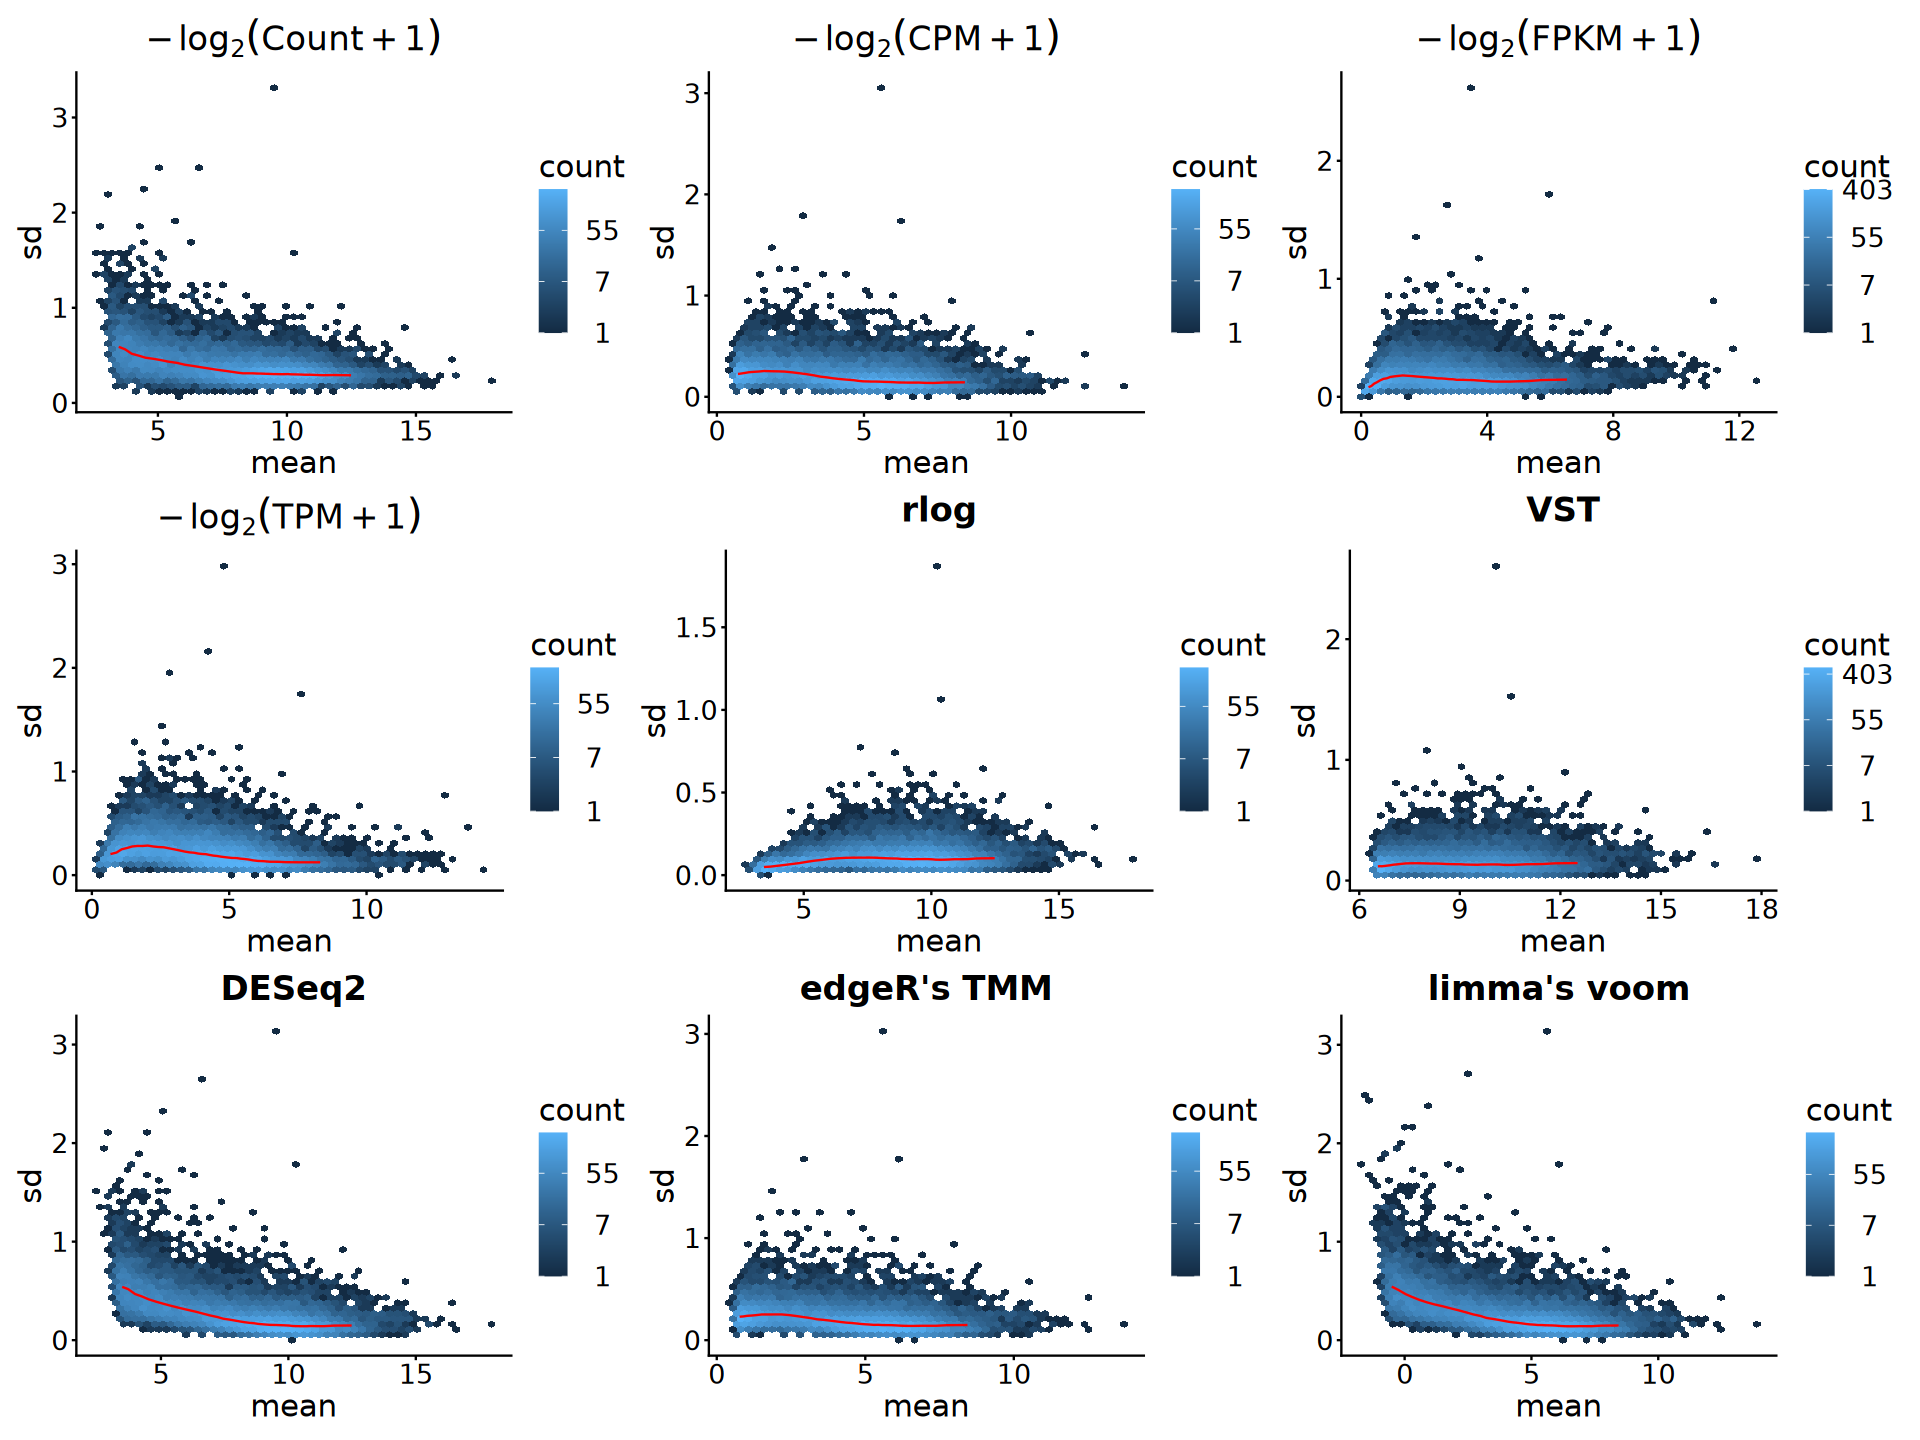

In [41]:
options(repr.plot.width = 16, repr.plot.height = 12)
(p1 + p2 + p3) / (p4 + p5 + p6) / (p7 + p8 + p9)

# 4. Exploration

In [42]:
norm_mat <- log2(tpm + 1)
norm_vs <- assay(rld)

### 1). Overview

In [43]:
plot_df <- colData(eSet) |> as.data.frame() |>
    arrange(Group, Replicate) |> 
    rownames_to_column(var = "Sample") |>
    mutate(
        librarySize = colSums(assay(eSet))[Sample], 
        Sample = gsub("_", "\n", Sample), 
        Sample = factor(Sample, levels = Sample))

plot_df

Sample,Cell,Gene,Group,Replicate,librarySize
<fct>,<chr>,<chr>,<fct>,<fct>,<dbl>
Ctrl rep1,ED-CPCs,Bcl6,Ctrl,rep1,15794798
Ctrl rep2,ED-CPCs,Bcl6,Ctrl,rep2,14993775
Ctrl rep3,ED-CPCs,Bcl6,Ctrl,rep3,15208562
Ctrl rep4,ED-CPCs,Bcl6,Ctrl,rep4,14312136
cKO rep1,ED-CPCs,Bcl6,cKO,rep1,24925731
cKO rep2,ED-CPCs,Bcl6,cKO,rep2,17226343
cKO rep3,ED-CPCs,Bcl6,cKO,rep3,17039378
cKO rep4,ED-CPCs,Bcl6,cKO,rep4,15595593


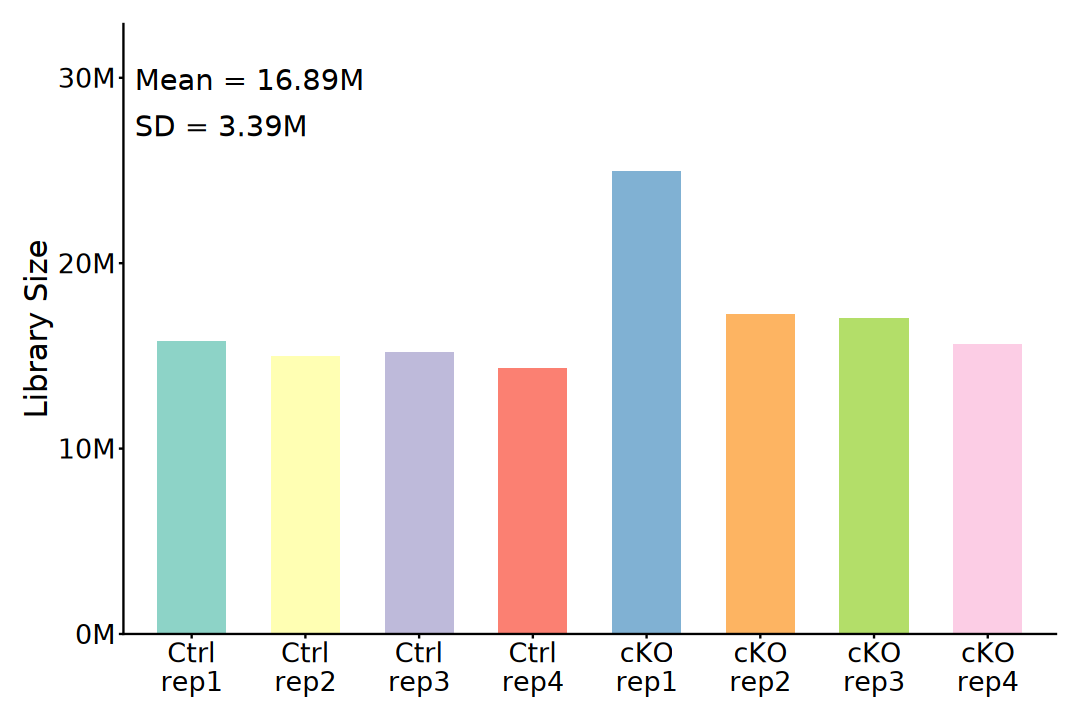

In [44]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(plot_df, aes(x = Sample, y = librarySize)) +
    geom_col(aes(fill = Sample), width = 0.6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.2,
        label = paste0("Mean = ", round(
            mean(plot_df$librarySize) / 1e6 , 2), "M"),
        hjust = 0, size = 6) +
    annotate(
        geom = "text", x = 0.5, y = max(plot_df$librarySize) * 1.1,
        label = paste0("SD = ", round(
            sd(plot_df$librarySize) * 1e-6 , 2), "M"),
        hjust = 0, size = 6) +
    scale_y_continuous(
        labels = scales::label_number(scale = 1e-6, suffix = "M"),
        expand = expansion(mult = c(0, 0.1))) +
    scale_fill_brewer(palette = "Set3") +
    labs(x = NULL, y = "Library Size") +
    theme_classic() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.position = "none",
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [45]:
# remotes::install_github("psyteachr/introdataviz")
suppressPackageStartupMessages(library(introdataviz))

Warning message:
"Using the `size` aesthetic with geom_polygon was deprecated in ggplot2 3.4.0.
ℹ Please use the `linewidth` aesthetic instead."


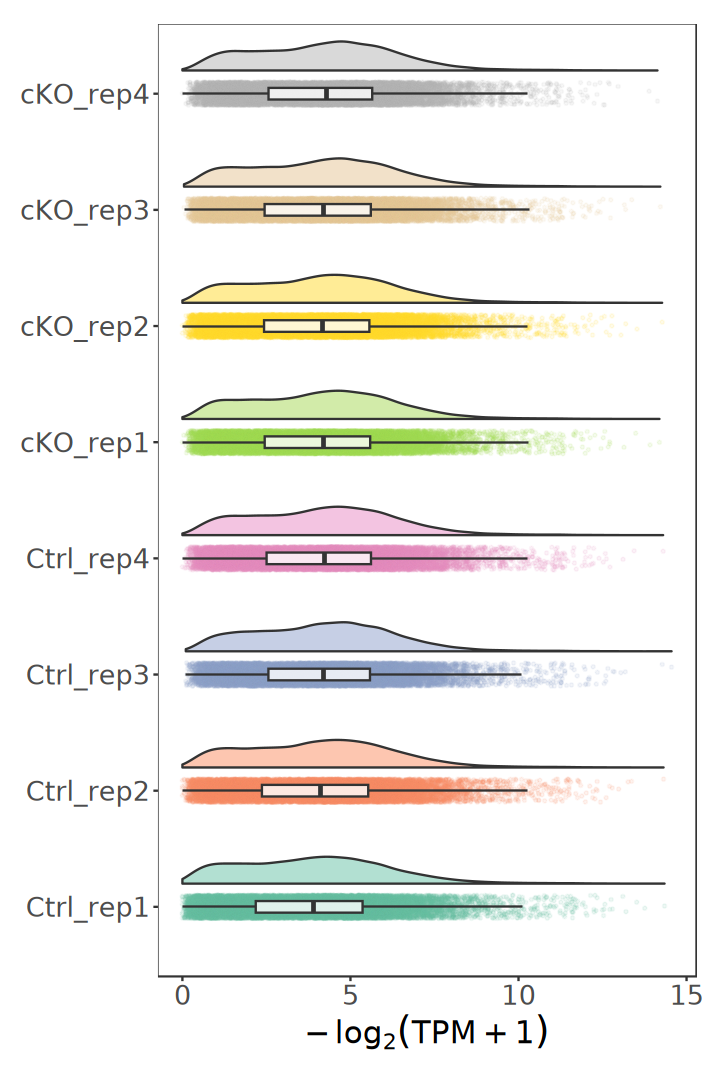

In [46]:
options(repr.plot.width = 6, repr.plot.height = 9)

norm_mat |> as.data.frame() |> 
    pivot_longer(
        cols = everything(), names_to = "Sample", 
        values_to = "Value") |>
    mutate(
        Sample = factor(Sample, levels = colnames(norm_mat))) |>
    ggplot(aes(x = Sample, y = Value)) +
        geom_flat_violin(
            aes(fill = Sample), width = 0.5, alpha = 0.5,
            position = position_nudge(x = 0.2, y = 0)) +
        geom_point(
            aes(color = Sample), size = 0.5, alpha = 0.1,
            position = position_jitter(width = 0.1)) + 
        geom_boxplot(
            width = 0.1, alpha = 0.8, outlier.shape = NA) +
        scale_fill_brewer(palette = "Set2") +
        scale_colour_brewer(palette = "Set2") +
        coord_flip() +
        labs(x = NULL, y = expression(-log[2](TPM+1))) +
        theme_test() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.position = "none",
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))

## 2). PCA

In [47]:
top_var_idx <- norm_mat |>
    rowSds() |>
    # (\(m) rowSds(m) / rowMeans2(m))() |> # CV
    tibble::enframe(name = "row", value = "sd") |>
    slice_max(order_by = sd, n = 2000) |>
    pull(row)
# CV can eliminate the bias that "high abundance tends to have large variance".

In [48]:
pca_res <- norm_mat[top_var_idx, ] |> t() |> 
    prcomp(center = TRUE, scale. = FALSE)

per_var <- round(100 * pca_res$sdev^2 / sum(pca_res$sdev^2), 2)

pca_df <- merge(pca_res$x, colData(eSet), by = "row.names")

head(pca_df)

,Row.names,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,Cell,Gene,Group,Replicate
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<fct>,<fct>
1,cKO_rep1,10.003472,15.298521,5.5421662,-1.2659226,-1.3997740,-0.9694023,6.0115868,8.520962e-15,ED-CPCs,Bcl6,cKO,rep1
2,cKO_rep2,7.027477,17.892834,6.3680109,-1.0185673,-1.6338258,2.0129025,-5.4751191,8.729129e-15,ED-CPCs,Bcl6,cKO,rep2
3,cKO_rep3,7.302092,4.345580,-7.7080758,0.8973941,4.3974078,-7.7043238,-1.3698412,-8.243406e-15,ED-CPCs,Bcl6,cKO,rep3
4,cKO_rep4,14.298279,-2.885132,-9.2628963,3.8053958,2.2901879,6.7374460,0.7173106,-5.235395e-15,ED-CPCs,Bcl6,cKO,rep4
5,Ctrl_rep1,-30.412959,6.364627,-0.4900060,8.0881727,-0.1508501,0.4554260,0.5282430,-1.150469e-14,ED-CPCs,Bcl6,Ctrl,rep1
6,Ctrl_rep2,-14.644752,-4.864521,-0.8991656,-12.4091387,4.1126619,1.7261355,0.2599594,-1.111611e-14,ED-CPCs,Bcl6,Ctrl,rep2


In [49]:
p1 <- ggplot(pca_df, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = bquote("PCA for" ~ -log[2](TPM+1)), 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [50]:
pca_res <- plotPCA(
    rld, intgroup = c("Group", "Replicate"), 
    ntop = 2000, returnData = TRUE)

per_var <- round(100 * attr(pca_res, "percentVar"))

using ntop=2000 top features by variance



In [51]:
p2 <- ggplot(pca_res, aes(PC1, PC2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(
        title = "PCA for rlog", 
        x = paste0("PC1: ", per_var[1], "% variance"),
        y = paste0("PC2: ", per_var[2], "% variance")) +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

In [52]:
# Generalized principal component analysis (GLM-PCA)
# suppressPackageStartupMessages(library(glmpca))
gpca <- glmpca::glmpca(assay(eSet)[top_var_idx, ], L = 2)

gpca_df <- merge(gpca$factors, colData(eSet), by = "row.names")

gpca_df

DataFrame with 8 rows and 7 columns
    Row.names      dim1       dim2        Cell        Gene    Group Replicate
  <character> <numeric>  <numeric> <character> <character> <factor>  <factor>
1    cKO_rep1  14.35095   0.818144     ED-CPCs        Bcl6     cKO       rep1
2    cKO_rep2  14.03607  -1.445146     ED-CPCs        Bcl6     cKO       rep2
3    cKO_rep3   8.78823   3.573359     ED-CPCs        Bcl6     cKO       rep3
4    cKO_rep4   5.35024   7.621253     ED-CPCs        Bcl6     cKO       rep4
5   Ctrl_rep1 -10.05444 -21.798895     ED-CPCs        Bcl6     Ctrl      rep1
6   Ctrl_rep2  -9.56616  -5.390250     ED-CPCs        Bcl6     Ctrl      rep2
7   Ctrl_rep3 -16.16095  14.935674     ED-CPCs        Bcl6     Ctrl      rep3
8   Ctrl_rep4  -6.74394   1.685860     ED-CPCs        Bcl6     Ctrl      rep4

In [53]:
p3 <- ggplot(gpca_df, aes(dim1, dim2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    labs(title = "GLM-PCA for raw count", x = "PC1", y = "PC2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

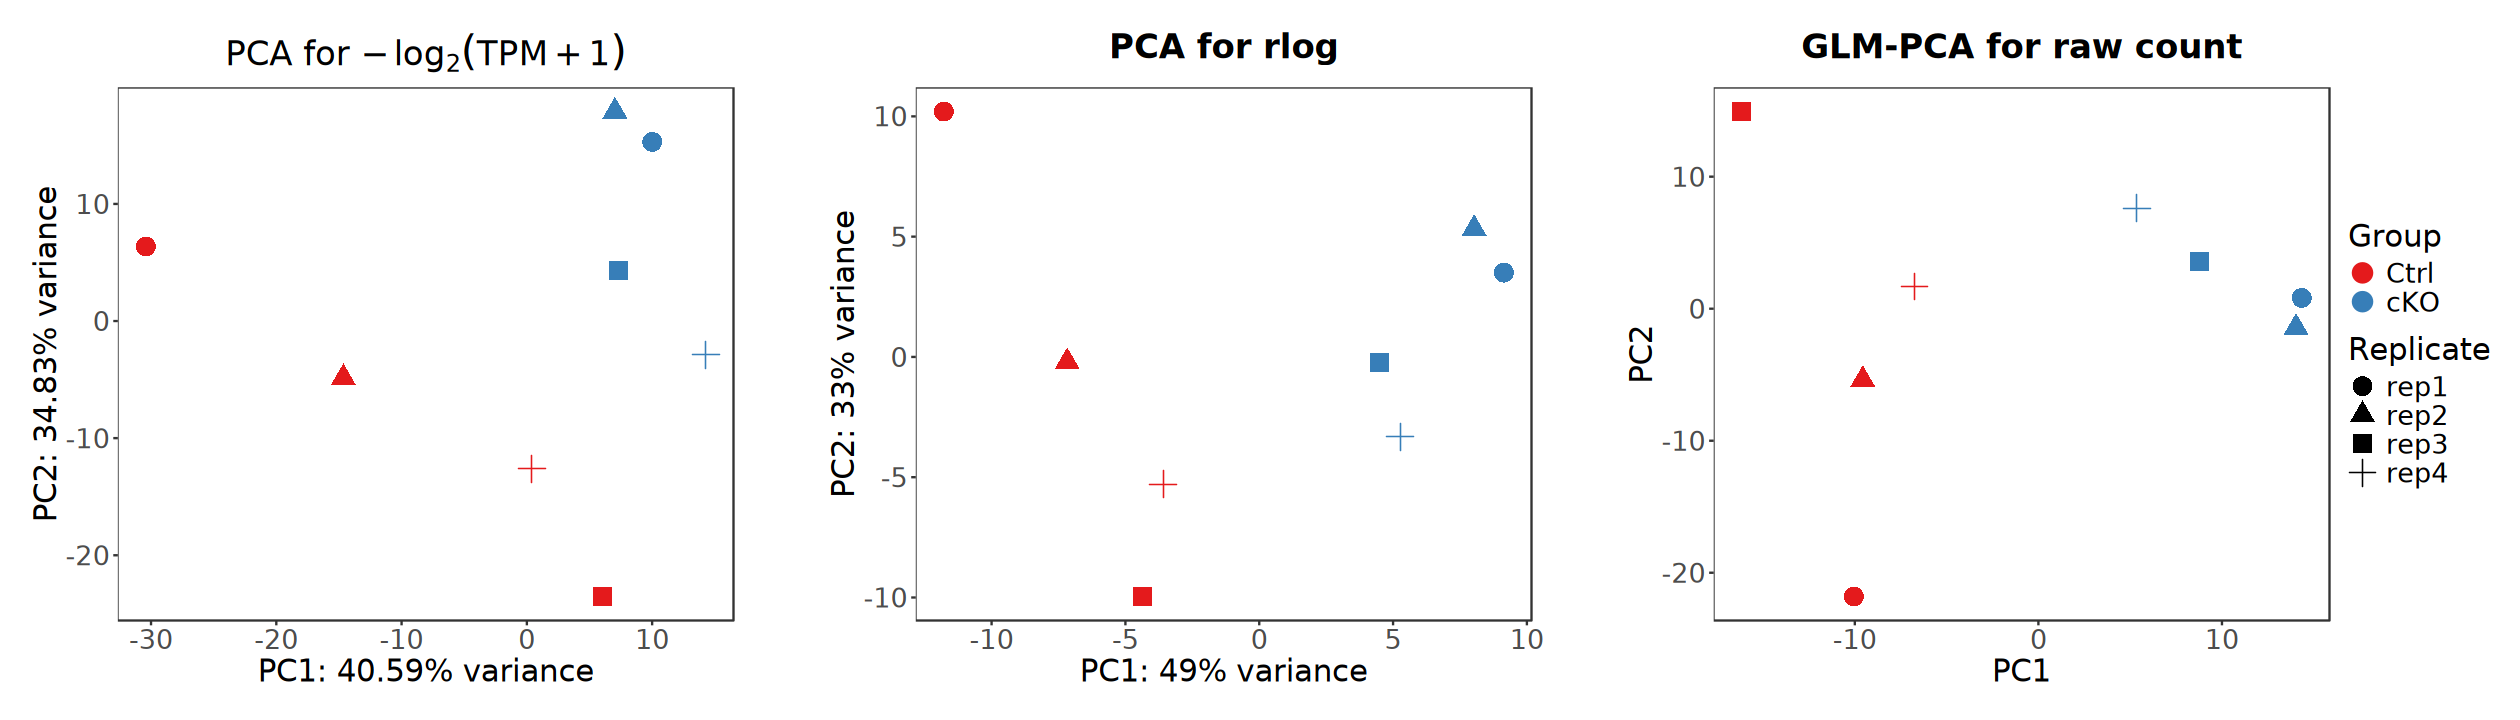

In [54]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(nrow = 1, guides = "collect", 
                widths = c(1, 0.05, 1, 0.05, 1))

## 3). MDS

> Multidimensional scaling

In [55]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

mds <- colData(eSet) |> as.data.frame() |>
    cbind(cmdscale(as.matrix(dist_mat)))

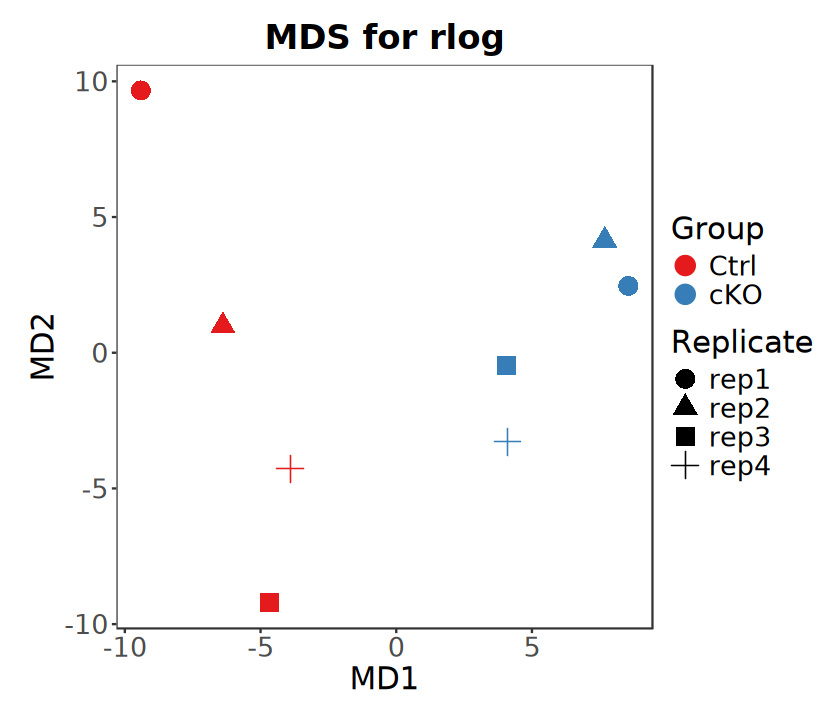

In [56]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(mds, aes(x = `1`, y = `2`)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("MDS for" ~ -log[2](TPM+1))) + 
    ggtitle("MDS for rlog") + 
    labs(x = "MD1", y = "MD2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 4). PCoA

> Principal coordinate analysis

In [57]:
# 1. Calculate Bray-Curtis distance on the transposed count matrix
dist_mat <- norm_vs[top_var_idx, ] |> t() |> 
    vegan::vegdist(method = "bray")

# 2. Run PCoA
pcoa_res <- cmdscale(dist_mat, k = 2, eig = TRUE)

# 3. Prepare data for plot
pcoa_df <- merge(pcoa_res$points, colData(eSet), by = "row.names")

head(pcoa_df)

,Row.names,V1,V2,Cell,Gene,Group,Replicate
,<chr>,<dbl>,<dbl>,<chr>,<chr>,<fct>,<fct>
1,cKO_rep1,0.010137450,0.0040446295,ED-CPCs,Bcl6,cKO,rep1
2,cKO_rep2,0.008716632,0.0062177655,ED-CPCs,Bcl6,cKO,rep2
3,cKO_rep3,0.004975078,-0.0002727752,ED-CPCs,Bcl6,cKO,rep3
4,cKO_rep4,0.005729078,-0.0043057786,ED-CPCs,Bcl6,cKO,rep4
5,Ctrl_rep1,-0.013586960,0.0102725192,ED-CPCs,Bcl6,Ctrl,rep1
6,Ctrl_rep2,-0.007565047,0.0010684689,ED-CPCs,Bcl6,Ctrl,rep2


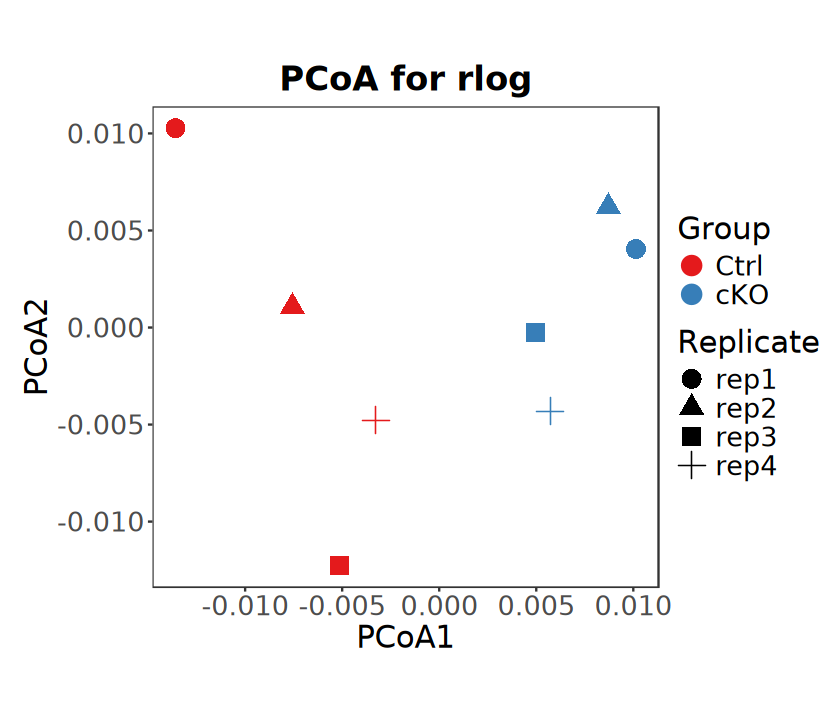

In [58]:
options(repr.plot.width = 7, repr.plot.height = 6)

ggplot(pcoa_df, aes(x = V1, y = V2)) +
    geom_point(aes(color = Group, shape = Replicate), size = 5) +
    scale_color_brewer(palette = "Set1") +
    coord_fixed() + 
    # ggtitle(bquote("PCoA for" ~ -log[2](TPM+1))) + 
    ggtitle("PCoA for rlog") + 
    labs(x = "PCoA1", y = "PCoA2") +
    guides(
        color = guide_legend(override.aes = list(size = 5)), 
        shape = guide_legend(override.aes = list(size = 5))) +
    theme_test() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

## 5). Sample Distance

In [59]:
ac <- colData(eSet) |> as.data.frame() |>
    dplyr::select(Replicate, Group)

In [60]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(eSet$Group)),
    levels(eSet$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(eSet$Replicate)),
    levels(eSet$Replicate))

anno_colors <- list(
    Group = group_colors,
    Replicate = replicate_colors)

colors <- colorRampPalette(brewer.pal(9, "Blues"))(255)

In [61]:
dist_mat <- norm_vs[top_var_idx, ] |> t() |> dist()

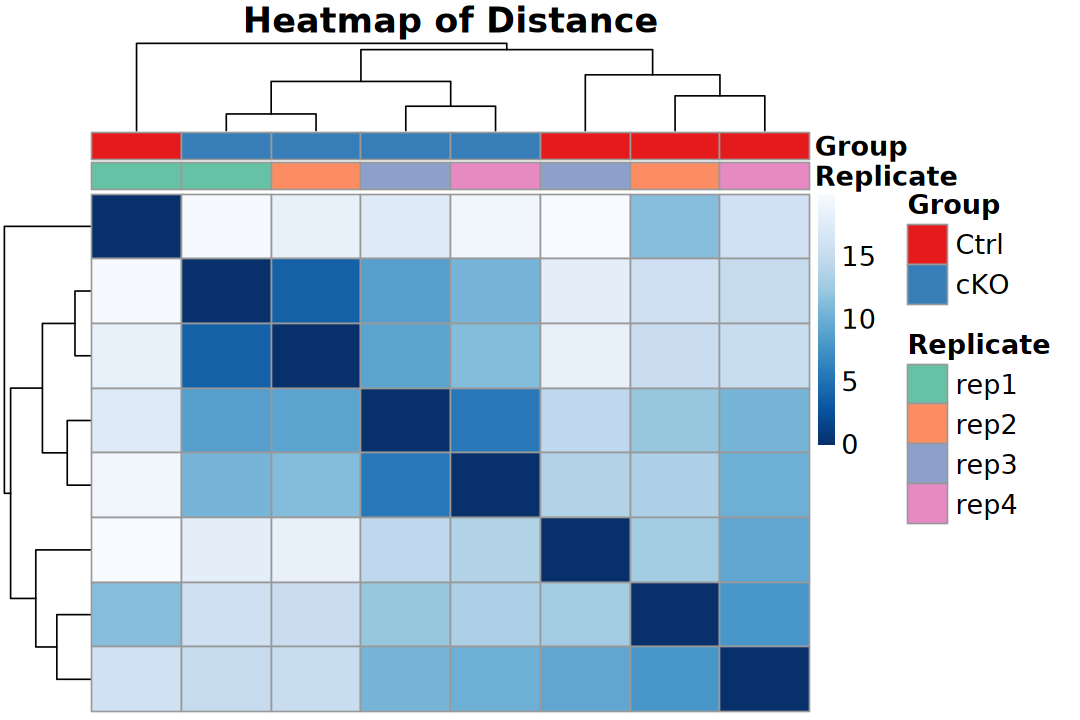

In [62]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = dist_mat,
    clustering_distance_cols = dist_mat,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [63]:
# This measure of dissimilarity between counts also takes the inherent variance structure 
# of counts into consideration when calculating the distances between samples. 
# The PoissonDistance function takes the original count matrix (not normalized) with samples
# as rows instead of columns, so we need to transpose the counts in dds.
# Calculating sample distances is to use the Poisson Distance

# suppressPackageStartupMessages(library(PoiClaClu))
poisd <- assay(eSet)[top_var_idx, ] |> t() |> 
    PoiClaClu::PoissonDistance()

dist_mat <- poisd$dd |> as.matrix()

colnames(dist_mat) <- colnames(eSet)

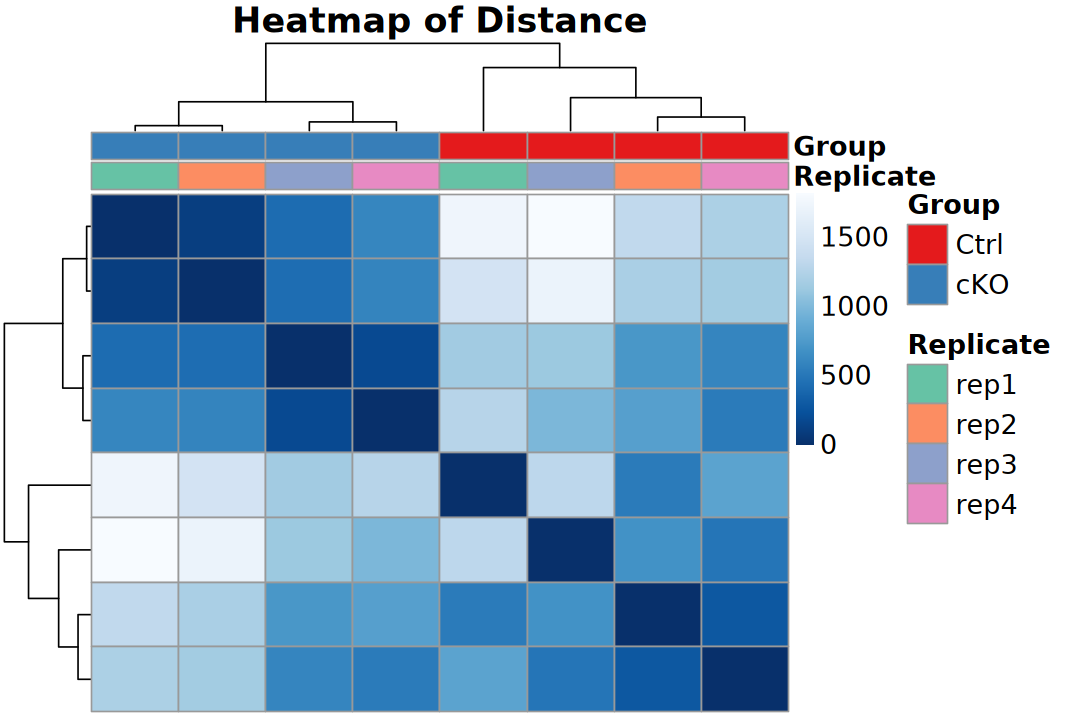

In [64]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(dist_mat),
    clustering_distance_rows = poisd$dd,
    clustering_distance_cols = poisd$dd,
    annotation_col = ac, col = rev(colors), 
    annotation_colors = anno_colors,
    main = "Heatmap of Distance", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

## 6). Sample Correlation

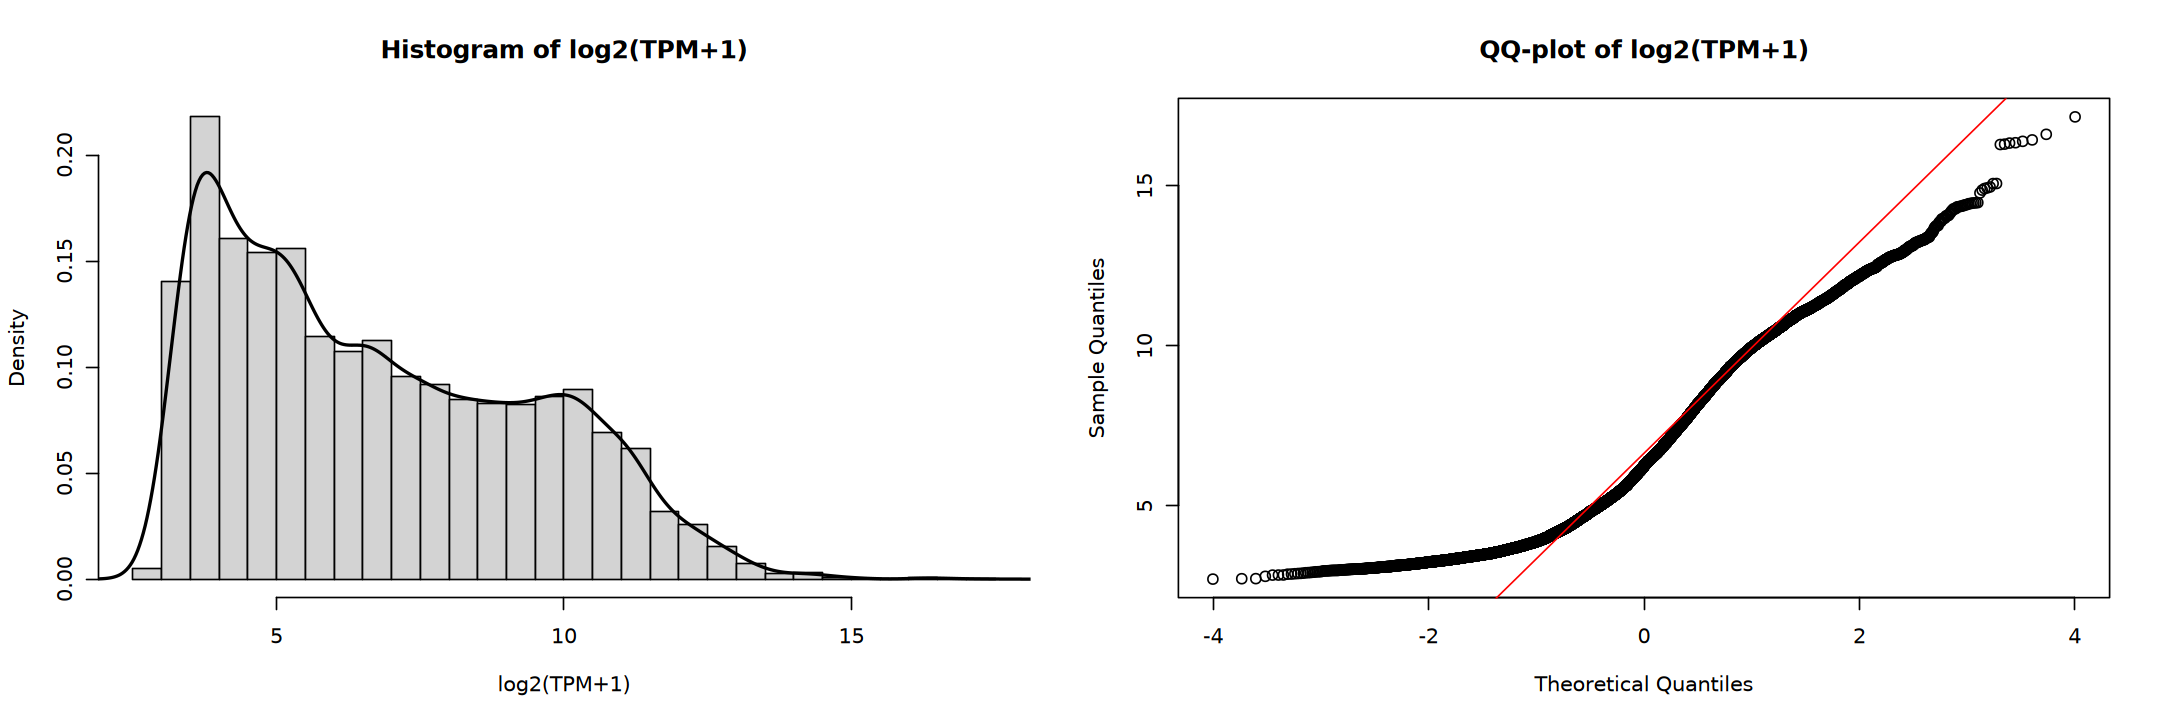

In [65]:
options(repr.plot.width = 18, repr.plot.height = 6)

par(mfrow = c(1, 2))
hist(
    norm_vs[top_var_idx, ], breaks = 50, probability = TRUE, 
    main = "Histogram of log2(TPM+1)", xlab = "log2(TPM+1)")
lines(density(norm_vs[top_var_idx, ]), lwd = 2)

qqnorm(
    norm_vs[top_var_idx, ], 
    main = "QQ-plot of log2(TPM+1)")
qqline(
    norm_vs[top_var_idx, ], col = "red")

par(mfrow = c(1, 1))

In [66]:
# cor_mat <- cor(norm_vs[top_var_idx, ], method = "pearson")
cor_mat <- cor(norm_vs[top_var_idx, ], method = "spearman")

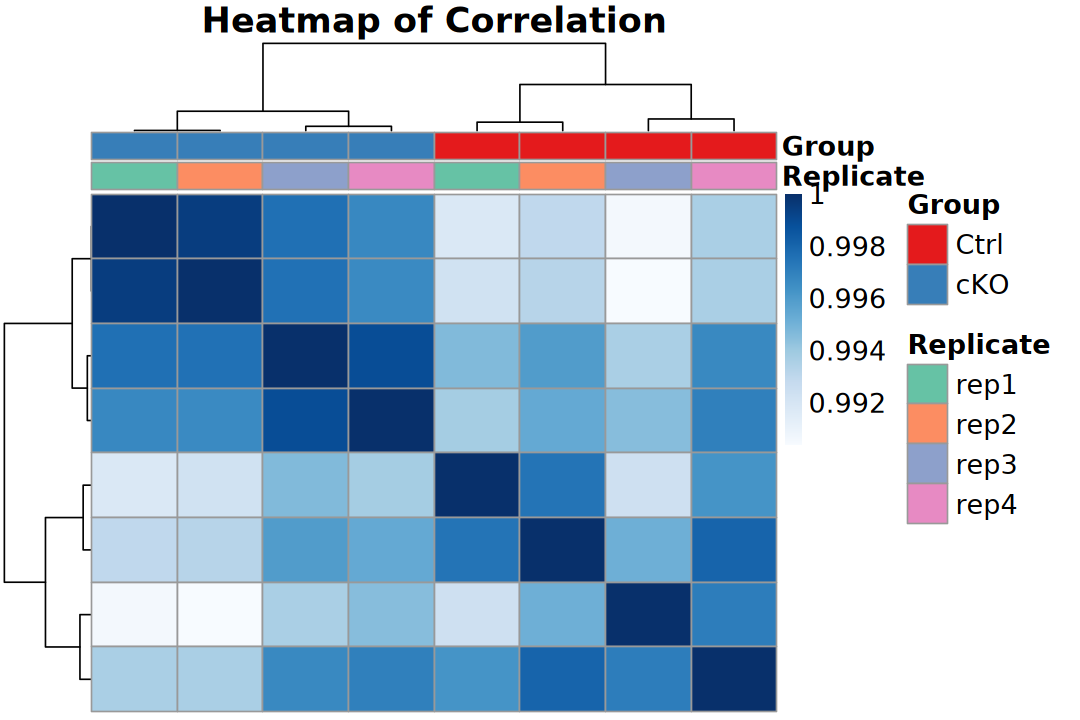

In [67]:
options(repr.plot.width = 9, repr.plot.height = 6)

pheatmap::pheatmap(
    as.matrix(cor_mat), 
    clustering_distance_rows = "correlation",
    clustering_distance_cols = "correlation",
    annotation_col = ac, col = colors, 
    annotation_colors = anno_colors,
    main = "Heatmap of Correlation", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

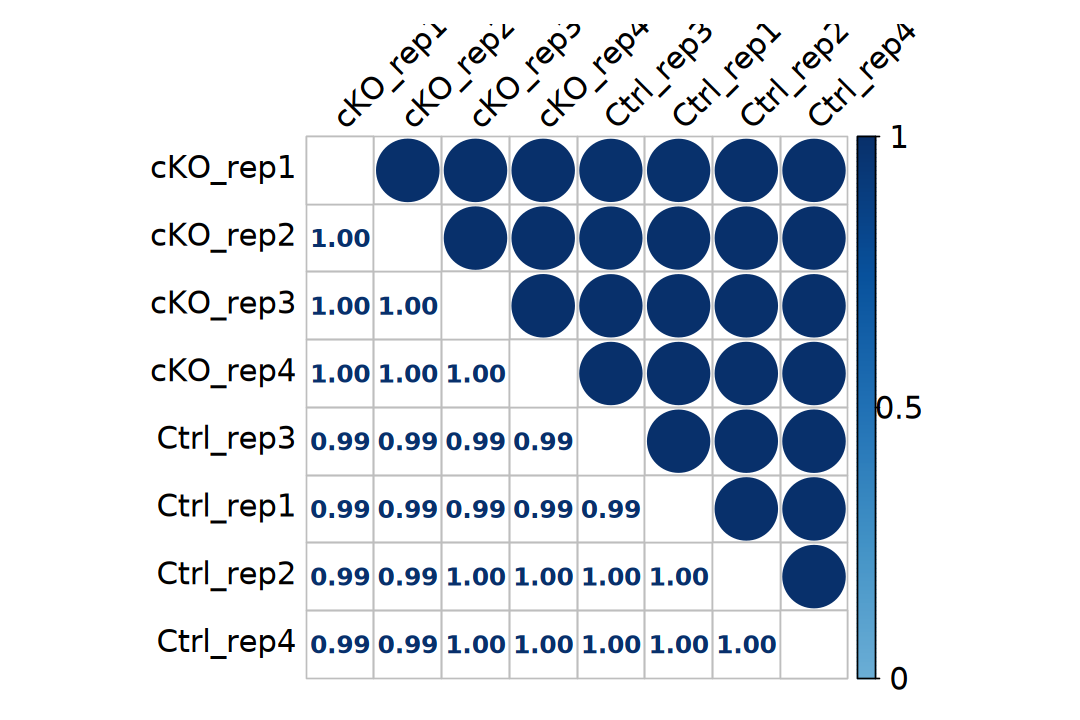

In [68]:
# suppressPackageStartupMessages(library(corrplot))
options(repr.plot.width = 9, repr.plot.height = 6)

corrplot::corrplot.mixed(
    cor_mat, order = 'hclust', upper.col = colors, 
    tl.pos = "lt", tl.cex = 1.5, tl.col = "black", tl.srt = 45, 
    number.cex = 1.2, diag = "n", col.lim = c(0, 1), 
    lower.col = colors, rect.col = "grey50", 
    cl.cex = 1.5, cl.length = 3, mar = c(1, 0, 1, 0))

## 7). Heatmap

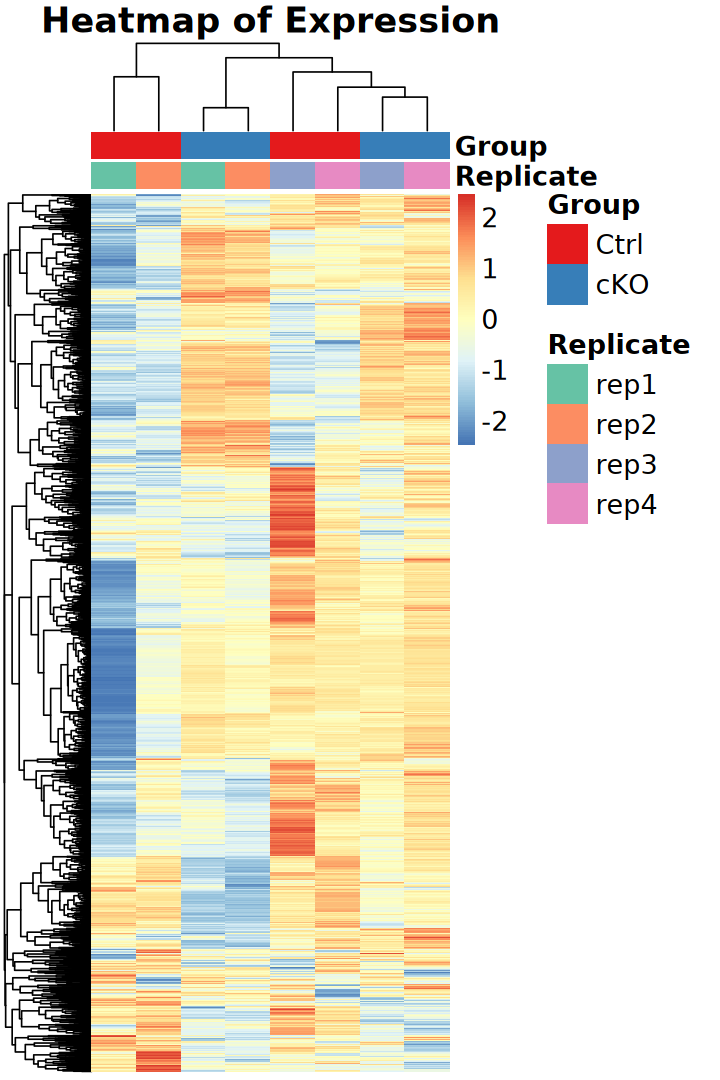

In [69]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    norm_mat[top_var_idx, ], scale = "row", 
    annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

# 5. DEGs

In [70]:
logfc_cutoff <- log2(1.2)
p_cutoff <- 0.05

## 1). DESeq2

> median of ratios for normalization

In [71]:
design(dds)

~Group

In [72]:
dds <- DESeq(dds)

using pre-existing size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [73]:
resultsNames(dds)

[1] "Intercept"         "Group_cKO_vs_Ctrl"

### a). Standard

In [74]:
res <- results(dds, lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, name = "Group_cKO_vs_Ctrl", 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
# res <- results(
#     dds, contrast = c("Group", "cKO", "Ctrl"), 
#     lfcThreshold = logfc_cutoff, alpha = p_cutoff)
summary(res)


out of 16126 with nonzero total read count
adjusted p-value < 0.05
LFC > 0.26 (up)    : 149, 0.92%
LFC < -0.26 (down) : 111, 0.69%
outliers [1]       : 1, 0.0062%
low counts [2]     : 0, 0%
(mean count < 7)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [75]:
deseq2_result <- res |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_result$result)
head(deseq2_result)


   Up  Down    NS 
  149   111 15866 

,baseMean,logFC,lfcSE,stat,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,249.30158,0.036322264,0.27884709,0.13025871,0.9334126,0.9999998,NS,Xkr4,protein_coding,6094
ENSMUSG00000025902.13,167.02311,0.173345007,0.17257668,1.00445210,0.7040920,0.9999998,NS,Sox17,protein_coding,4772
ENSMUSG00000103922.1,92.86053,-0.351441719,0.18664715,-1.88292037,0.3183682,0.9999998,NS,Gm6123,processed_pseudogene,1069
ENSMUSG00000033845.13,1961.82831,-0.039926311,0.10937894,-0.36502741,0.9821178,0.9999998,NS,Mrpl15,protein_coding,8487
ENSMUSG00000025903.14,1311.32967,0.114366619,0.09378731,1.21942524,0.9435635,0.9999998,NS,Lypla1,protein_coding,7145
ENSMUSG00000033813.15,2140.19639,0.002668176,0.08168960,0.03266238,0.9998537,0.9999998,NS,Tcea1,protein_coding,3017


### b). LFC Shrink

> Shrinkage of effect size (LFC estimates) is useful for visualization and ranking of genes.

In [76]:
res_lfc <- lfcShrink(dds, coef = "Group_cKO_vs_Ctrl", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 16126 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 1196, 7.4%
LFC < 0 (down)     : 1124, 7%
outliers [1]       : 1, 0.0062%
low counts [2]     : 626, 3.9%
(mean count < 12)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [77]:
deseq2_lfc_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(deseq2_lfc_result$result)
head(deseq2_lfc_result)


   Up  Down    NS 
  777   662 14687 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000051951.5,249.30158,0.00859136,0.13419598,0.89636174,0.9586490,NS,Xkr4,protein_coding,6094
ENSMUSG00000025902.13,167.02311,0.08234547,0.12748292,0.31516075,0.5902219,NS,Sox17,protein_coding,4772
ENSMUSG00000103922.1,92.86053,-0.19101547,0.17781958,0.05971116,0.2357868,NS,Gm6123,processed_pseudogene,1069
ENSMUSG00000033845.13,1961.82831,-0.02642761,0.08959165,0.71509095,0.8732563,NS,Mrpl15,protein_coding,8487
ENSMUSG00000025903.14,1311.32967,0.08628920,0.08436320,0.22268284,0.4916423,NS,Lypla1,protein_coding,7145
ENSMUSG00000033813.15,2140.19639,0.00218044,0.07203766,0.97394383,0.9900525,NS,Tcea1,protein_coding,3017


### Evaluate DEGs

In [78]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [79]:
genes_up <- list(
    raw = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    raw = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    lfc = deseq2_lfc_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [80]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

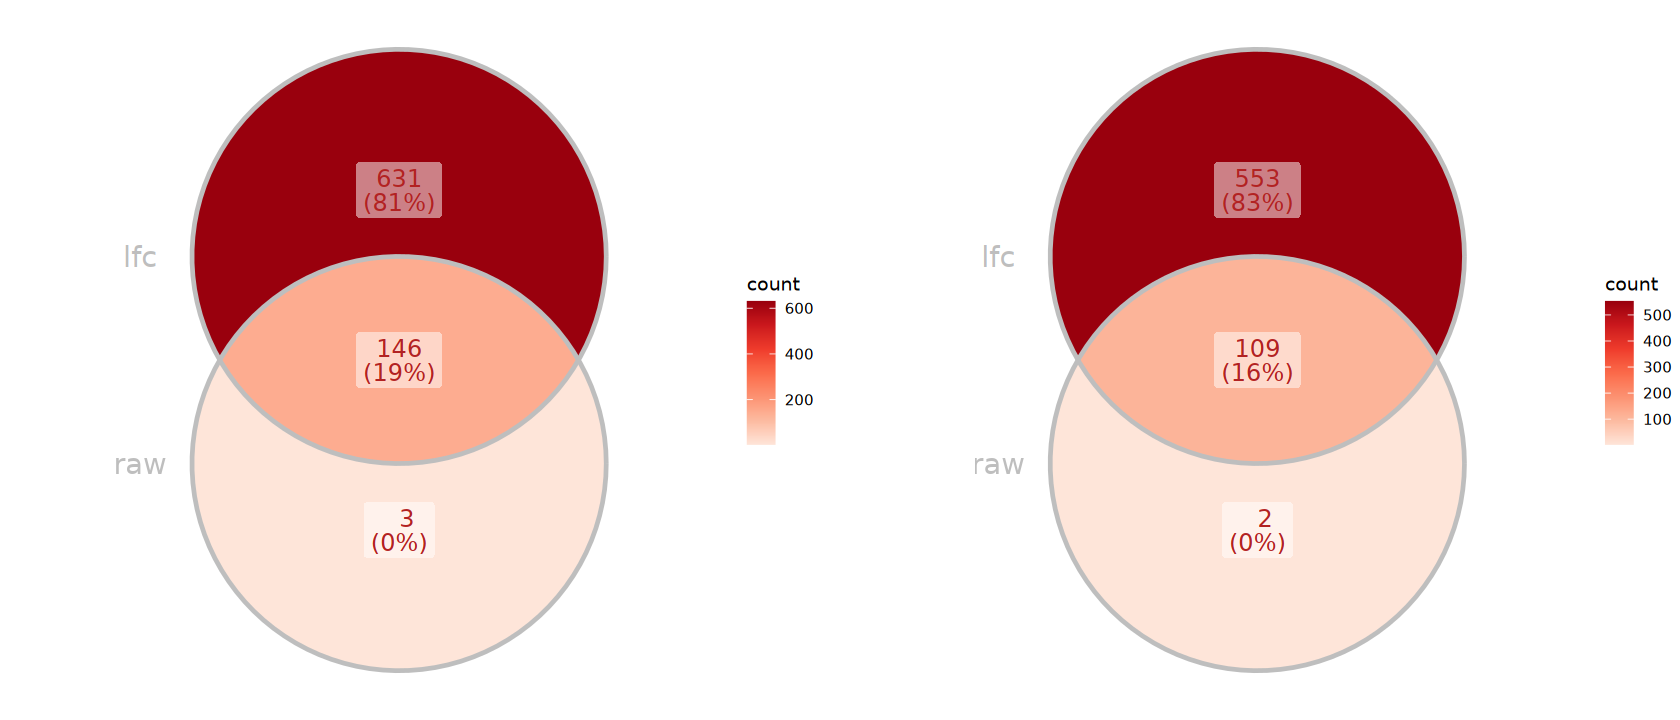

In [81]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 2). edgeR

> Trimmed Mean of M-values (TMM)

| Pipeline | Advantages | Application | Estimating dispersions | Fitting model | Testing methods | Notes |
| - | - | - | - | - | - | - |
| Classic pipeline (edgeR v1) | - | Single factor design | quantile-adjusted conditional maximum likelihood (qCML) method | Negative binomial model | Exact test (like Fisher’s exact test) | - |
| Negative binomial GLM framework (edgeR v2) | - | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | Negative binomial - Generalized linear model (NB GLM) | Likelihood ratio test (LRT) | - |
| Quasi-likelihood pipeline (edgeR v3) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Cox-Reid profile-adjusted likelihood (CR) method | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | - |
| Quasi-likelihood pipeline (edgeR v4) | Robustness and highly reliable false discovery rate (FDR) control | Multiple factors design | Estimates a constant NB dispersion based on the most highly expressed genes | only the trended NB dispersions are used in fitting the QL GLM | Quasi-likelihood F-test (QLF) | Default and Recommended approach in edgeR |

### a). Classic pipeline

In [82]:
dgel_classic <- estimateDisp(dgel)
# # 1. Estimate common dispersion
# dgel <- estimateCommonDisp(dgel)
# # 2. Estimate tagwise dispersions
# dgel <- estimateTagwiseDisp(dgel)

Using classic mode.



In [83]:
# exact test
et <- exactTest(dgel_classic, pair = c("Ctrl", "cKO"))

In [84]:
edger_classic_result <- topTags(et, n = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_classic_result$result)
head(edger_classic_result)


   Up  Down    NS 
  906   791 14191 

,symbol,type,basepairs,logFC,logCPM,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000022508.5,Bcl6,protein_coding,6700,5.906148,7.541915,0.000000e+00,0.000000e+00,Up
ENSMUSG00000075602.10,Ly6a,protein_coding,1205,4.309094,2.196759,3.557334e-68,2.825946e-64,Up
ENSMUSG00000032315.6,Cyp1a1,protein_coding,2787,3.928734,1.541543,4.284128e-41,2.268874e-37,Up
ENSMUSG00000062327.10,T,protein_coding,2315,1.504356,5.214535,1.365046e-36,5.421964e-33,Up
ENSMUSG00000028640.11,Tfap2c,protein_coding,3679,1.131456,5.675060,5.620409e-33,1.785941e-29,Up
ENSMUSG00000029646.3,Cdx2,protein_coding,2261,3.051737,2.460603,2.198215e-29,5.820874e-26,Up


### b). Negative binomial GLM framework

In [85]:
design <- model.matrix(~ group, data = dgel$samples) # include intercept
design

,(Intercept),groupcKO
Ctrl_rep1,1,0
Ctrl_rep2,1,0
Ctrl_rep3,1,0
Ctrl_rep4,1,0
cKO_rep1,1,1
cKO_rep2,1,1
cKO_rep3,1,1
cKO_rep4,1,1


In [86]:
dgel_nbglm <- estimateDisp(dgel, design)
# # Estimate common dispersion
# dgel <- estimateGLMCommonDisp(dge, design)
# # Estimate trended dispersions
# dgel <- estimateGLMTrendedDisp(dgel, design)
# # Estimate tagwise dispersions
# dgel <- estimateGLMTagwiseDisp(dgel, design)

In [87]:
# likelihood ratio test
fit <- glmFit(dgel_nbglm, design)
lrt <- glmLRT(fit, coef = 2)

In [88]:
edger_glm_lrt_result <- topTags(lrt, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_lrt_result$result)
head(edger_glm_lrt_result)


   Up  Down    NS 
  930   814 14144 

,symbol,type,basepairs,logFC,logCPM,LR,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000022508.5,Bcl6,protein_coding,6700,5.906148,7.541942,1460.7671,1.311645e-319,2.083942e-315,Up
ENSMUSG00000075602.10,Ly6a,protein_coding,1205,4.309182,2.197086,312.9078,5.079229e-70,4.034940e-66,Up
ENSMUSG00000032315.6,Cyp1a1,protein_coding,2787,3.928812,1.541883,183.8243,7.087094e-42,3.753325e-38,Up
ENSMUSG00000062327.10,T,protein_coding,2315,1.504343,5.214591,159.3754,1.549228e-36,6.153535e-33,Up
ENSMUSG00000028640.11,Tfap2c,protein_coding,3679,1.131458,5.675095,142.8749,6.260187e-33,1.989237e-29,Up
ENSMUSG00000029646.3,Cdx2,protein_coding,2261,3.051812,2.460935,128.9377,6.998194e-30,1.853122e-26,Up


### c). Quasi-likelihood pipeline (edgeR v3)

In [89]:
design <- model.matrix(~ group, data = dgel$samples) # include intercept

In [90]:
dgel_nbglm <- estimateDisp(dgel, design)

In [91]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel_nbglm, design)
qlf <- glmQLFTest(fit, coef = 2)

In [92]:
edger_glm_qlf_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_result$result)
head(edger_glm_qlf_result)


   Up  Down    NS 
  623   495 14770 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000022508.5,Bcl6,protein_coding,6700,5.906152,7.541942,2167.6249,5.886601e-14,9.352631e-10,Up
ENSMUSG00000075602.10,Ly6a,protein_coding,1205,4.309592,2.197086,338.1208,1.575198e-09,1.251337e-05,Up
ENSMUSG00000028640.11,Tfap2c,protein_coding,3679,1.131382,5.675095,214.3534,1.520372e-08,7.864421e-05,Up
ENSMUSG00000032315.6,Cyp1a1,protein_coding,2787,3.930212,1.541883,203.4462,2.191384e-08,7.864421e-05,Up
ENSMUSG00000062327.10,T,protein_coding,2315,1.504329,5.214591,195.2773,2.474956e-08,7.864421e-05,Up
ENSMUSG00000048385.9,Scrt1,protein_coding,4380,1.147660,4.314111,173.6349,4.558703e-08,1.207145e-04,Up


### d). Quasi-likelihood pipeline (edgeR v4)

In [93]:
design <- model.matrix(~ group, data = dgel$samples) # include intercept

In [94]:
# quasi-likelihood (QL) F-test
fit <- glmQLFit(dgel, design)
qlf <- glmQLFTest(fit, coef = 2)

In [95]:
edger_glm_qlf_v4_result <- topTags(qlf, n = Inf) |>
    as.data.frame() |> 
    dplyr::rename(padj = FDR, pvalue = PValue) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(edger_glm_qlf_v4_result$result)
head(edger_glm_qlf_v4_result)


   Up  Down    NS 
  622   495 14771 

,symbol,type,basepairs,logFC,logCPM,F,pvalue,padj,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000022508.5,Bcl6,protein_coding,6700,5.906150,7.540019,2183.8481,5.705339e-14,9.064643e-10,Up
ENSMUSG00000075602.10,Ly6a,protein_coding,1205,4.309454,2.164285,336.2945,1.627873e-09,1.293182e-05,Up
ENSMUSG00000028640.11,Tfap2c,protein_coding,3679,1.131370,5.672516,214.4351,1.524359e-08,8.071397e-05,Up
ENSMUSG00000032315.6,Cyp1a1,protein_coding,2787,3.929985,1.504134,203.3120,2.219233e-08,8.071397e-05,Up
ENSMUSG00000062327.10,T,protein_coding,2315,1.504398,5.210313,194.4720,2.540092e-08,8.071397e-05,Up
ENSMUSG00000048385.9,Scrt1,protein_coding,4380,1.147668,4.308632,173.5094,4.595113e-08,1.216786e-04,Up


### Evaluate DEGs

In [96]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [97]:
genes_up <- list(
    classic = edger_classic_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    classic = edger_classic_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_lrt = edger_glm_lrt_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_qlf = edger_glm_qlf_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    glm_v4 = edger_glm_qlf_v4_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [98]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

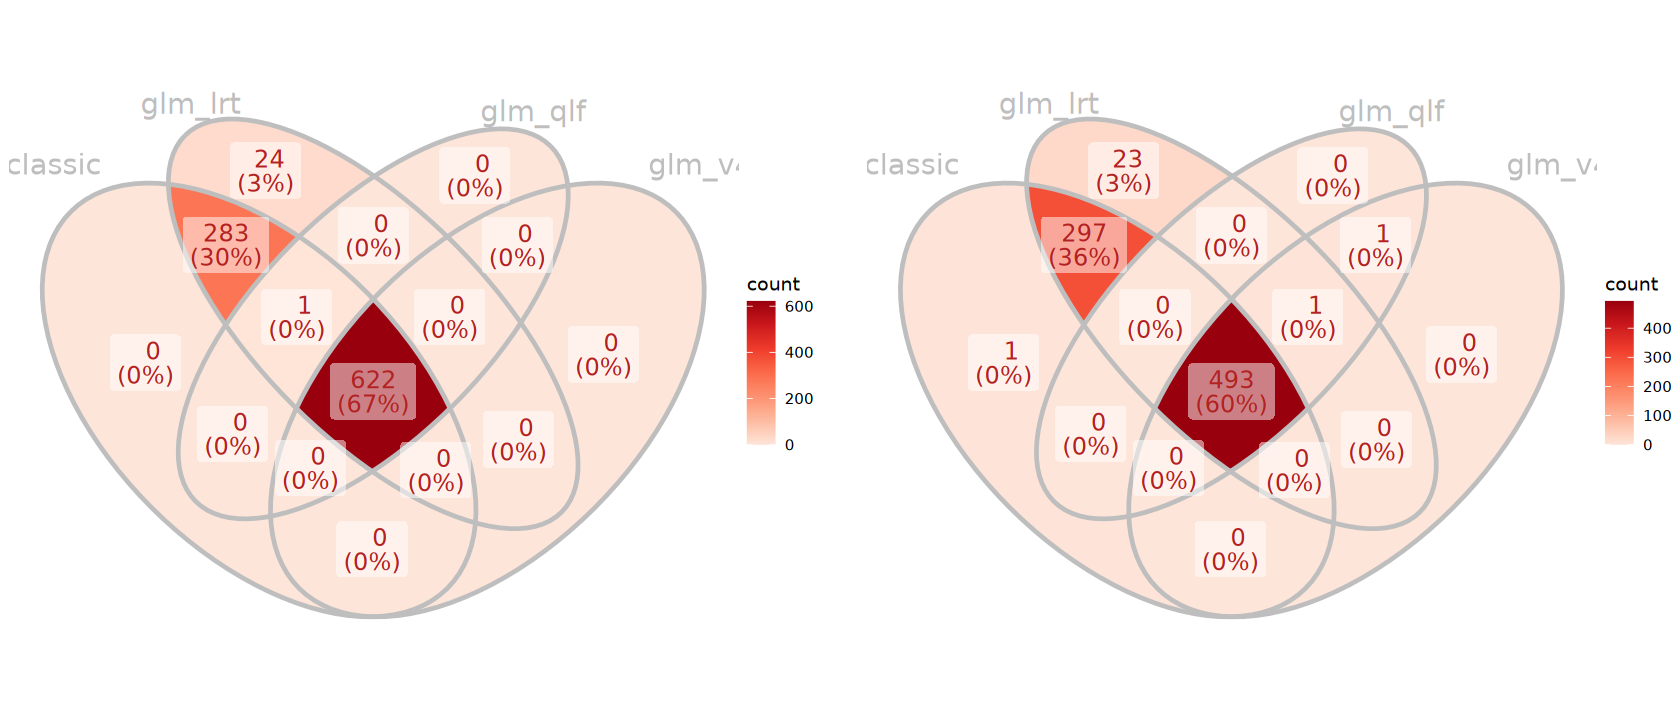

In [99]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## 3). limma

> In the limma approach to RNA-seq, read counts are converted to log2-counts-per-million (logCPM), and the mean-variance relationship is modeled either with precision weights or with an empirical Bayes prior trend. The precision weights approach is called “voom,” and the prior trend approach is called “limma-trend.”

### a). limma-trend

> If the sequencing depth is fairly consistent across the RNA samples, then the simplest and most reliable method for differential expression is to use limma-trend. This method usually works well if the ratio of the largest library size to the smallest is no more than about 3-fold. Few literature uses.

In [100]:
design <- model.matrix(~ group, data = dgel$samples)
design

,(Intercept),groupcKO
Ctrl_rep1,1,0
Ctrl_rep2,1,0
Ctrl_rep3,1,0
Ctrl_rep4,1,0
cKO_rep1,1,1
cKO_rep2,1,1
cKO_rep3,1,1
cKO_rep4,1,1


In [101]:
logCPM <- cpm(dgel, normalized.lib.sizes = TRUE, log = TRUE)
head(logCPM)

,Ctrl_rep1,Ctrl_rep2,Ctrl_rep3,Ctrl_rep4,cKO_rep1,cKO_rep2,cKO_rep3,cKO_rep4
ENSMUSG00000051951.5,2.846918,3.683093,4.590857,3.965466,4.121016,3.785800,3.970271,3.848350
ENSMUSG00000025902.13,3.509442,2.913860,3.012113,3.499684,3.578048,3.394720,3.252989,3.472142
ENSMUSG00000103922.1,2.665128,2.939683,2.308603,2.718916,2.416407,2.127601,2.226399,2.519184
ENSMUSG00000033845.13,7.187576,6.813493,6.798832,6.777208,6.902400,6.914083,6.856817,6.786698
ENSMUSG00000025903.14,6.195856,6.416021,6.111522,6.245963,6.469606,6.365450,6.328250,6.273253
ENSMUSG00000033813.15,6.933696,7.118433,6.864276,7.103209,7.010780,7.003361,7.032713,7.004204


In [102]:
# Linear Model for Series of Arrays
fit <- lmFit(logCPM, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit, trend = TRUE)

In [ ]:
limma_trend_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_trend_result <- topTable(efit, coef = "groupcKO", number = Inf) |> 
    as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        dgel$genes |> rownames_to_column("gene_id"), 
        by = "gene_id") |>
    column_to_rownames("gene_id")

table(limma_trend_result$result)
head(limma_trend_result)


   Up  Down    NS 
  596   461 14831 

,logFC,AveExpr,t,pvalue,padj,B,result,symbol,type,basepairs
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>
ENSMUSG00000022508.5,5.871251,5.568653,58.18376,7.683539e-15,1.220761e-10,16.240425,Up,Bcl6,protein_coding,6700
ENSMUSG00000028640.11,1.126813,5.561681,14.85802,1.562009e-08,1.240860e-04,9.655197,Up,Tfap2c,protein_coding,3679
ENSMUSG00000075602.10,4.068764,1.007625,14.00960,2.864070e-08,1.291260e-04,9.171878,Up,Ly6a,protein_coding,1205
ENSMUSG00000062327.10,1.511061,5.014155,13.83796,3.250906e-08,1.291260e-04,9.069109,Up,T,protein_coding,2315
ENSMUSG00000048385.9,1.141060,4.193738,13.20802,5.240146e-08,1.665109e-04,8.676544,Up,Scrt1,protein_coding,4380
ENSMUSG00000032265.14,-1.175590,5.549487,-12.67607,7.969398e-08,2.006681e-04,8.325144,Down,Tent5a,protein_coding,5703


### b). limma-voom

> When library sizes vary significantly between samples, the voom approach is technically more powerful than limma-trend.

In [104]:
design <- model.matrix(~ group, data = dgel$samples)

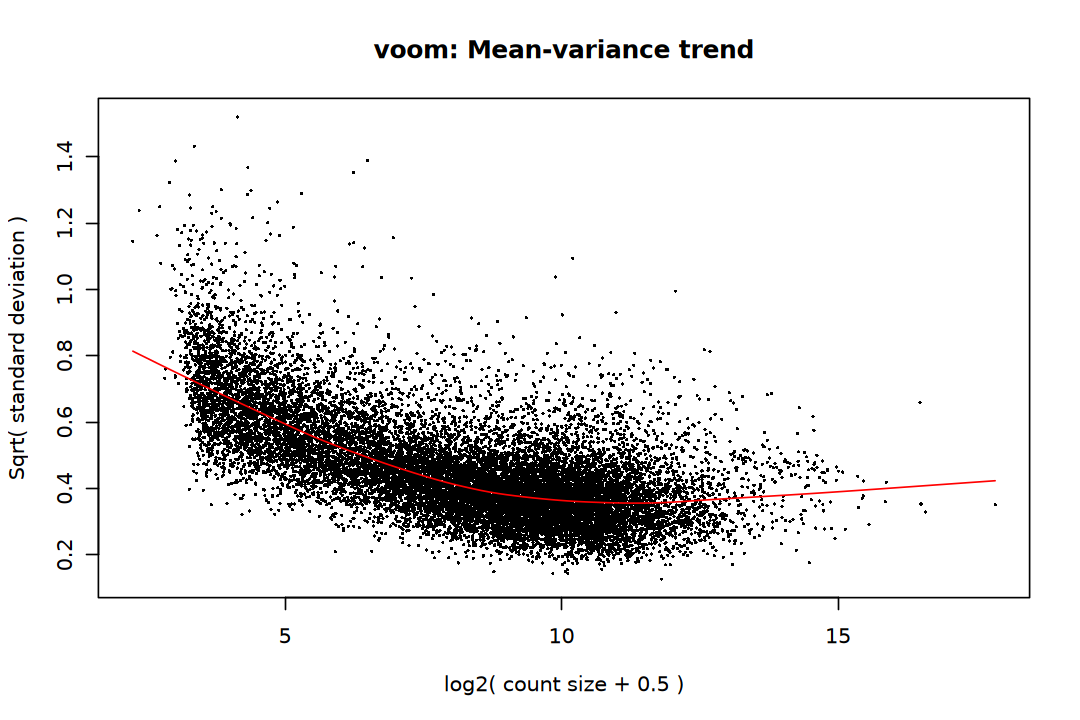

In [105]:
options(repr.plot.width = 9, repr.plot.height = 6)

norm_v <- voom(dgel, design, plot = TRUE)

In [106]:
# Linear Model for Series of Arrays
fit <- lmFit(norm_v, design)
# Empirical Bayes Statistics for Differential Expression
efit <- eBayes(fit)

In [ ]:
limma_voom_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voom_result <- topTable(efit, coef = "groupcKO", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voom_result$result)
head(limma_voom_result)


   Up  Down    NS 
  621   487 14780 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000022508.5,Bcl6,protein_coding,6700,5.889437,5.558556,40.71587,3.160786e-13,5.021856e-09,16.527727,Up
ENSMUSG00000028640.11,Tfap2c,protein_coding,3679,1.129078,5.558825,14.50721,1.875019e-08,1.184892e-04,10.056423,Up
ENSMUSG00000062327.10,T,protein_coding,2315,1.512771,5.009728,14.26199,2.237333e-08,1.184892e-04,9.852321,Up
ENSMUSG00000048385.9,Scrt1,protein_coding,4380,1.145990,4.186335,12.89784,6.303709e-08,2.003067e-04,8.815731,Up
ENSMUSG00000032265.14,Tent5a,protein_coding,5703,-1.174936,5.546506,-12.38714,9.527856e-08,2.522976e-04,8.477819,Down
ENSMUSG00000053024.14,Cntn2,protein_coding,9304,1.233541,5.495303,11.96192,1.359555e-07,3.034468e-04,8.126608,Up


### c). voomLmFit

> In recent versions of limma and edgeR, we now recommend voomLmFit as the preferred interface for RNA-seq analyses, replacing voom, lmFit, and voomWithQualityWeights. voomLmFit ensures unbiased estimation of the residual variances, even for genes that have no counts at all in some experimental conditions.
> - voomLmFit = voom transform + lmFit with weights

In [108]:
design <- model.matrix(~ group, data = dgel$samples)

In [109]:
# sample.weights = TRUE: estimating the empirical sample quality weights
fit <- voomLmFit(dgel, design = design, sample.weights = TRUE)
efit <- eBayes(fit)

First sample weights (min/max) 0.195109/2.496073

Final sample weights (min/max) 0.196008/2.416606



In [ ]:
limma_voomLmFit_result <- topTable(efit, coef = 2, number = Inf) |> 
# limma_voomLmFit_result <- topTable(efit, coef = "groupcKO", number = Inf) |> 
    as.data.frame() |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS")))

table(limma_voomLmFit_result$result)
head(limma_voomLmFit_result)


   Up  Down    NS 
 1103  1145 13640 

,symbol,type,basepairs,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
ENSMUSG00000022508.5,Bcl6,protein_coding,6700,5.927159,5.558556,37.33064,7.227568e-14,1.148316e-09,17.44237,Up
ENSMUSG00000062327.10,T,protein_coding,2315,1.624990,5.009728,17.62675,5.373489e-10,4.268700e-06,13.24008,Up
ENSMUSG00000028640.11,Tfap2c,protein_coding,3679,1.171181,5.558825,16.90702,8.737552e-10,4.627408e-06,12.94998,Up
ENSMUSG00000032265.14,Tent5a,protein_coding,5703,-1.145132,5.546506,-14.72551,4.325272e-09,1.695176e-05,11.44791,Down
ENSMUSG00000053024.14,Cntn2,protein_coding,9304,1.160495,5.495303,14.31869,5.967736e-09,1.695176e-05,11.11837,Up
ENSMUSG00000030111.9,A2m,protein_coding,7021,-1.405842,5.900790,-14.23132,6.401723e-09,1.695176e-05,11.06559,Down


### Evaluate DEGs

In [111]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [ ]:
genes_up <- list(
    trend = limma_trend_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    trend = limma_trend_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom = limma_voom_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    voom_wight = limma_voomLmFit_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [113]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

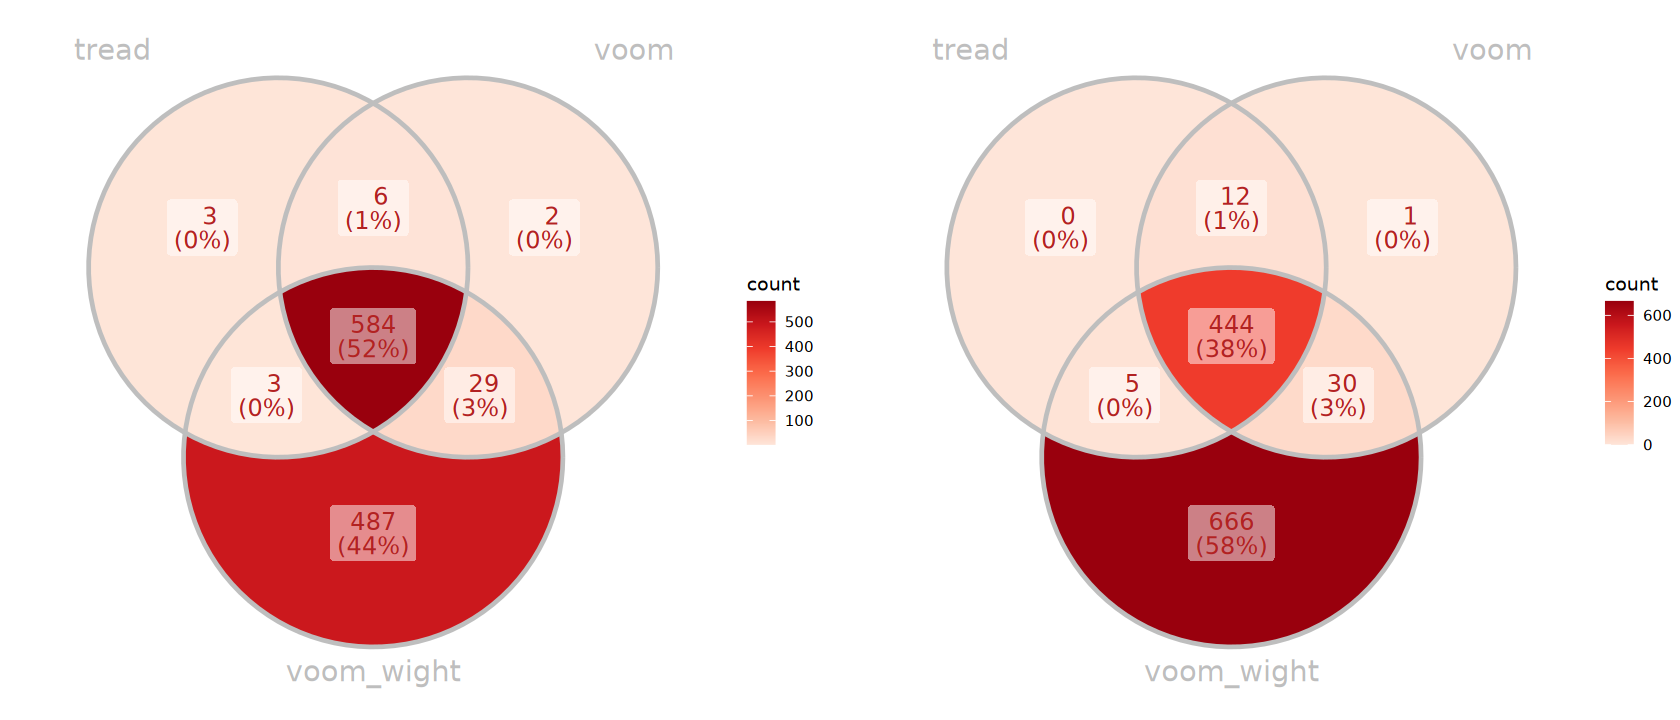

In [114]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

## DEGs Evaluation

In [115]:
add_label <- function(res, symbol_col = "symbol"){
    res |>
        tibble::rownames_to_column("gene_id") |>
        dplyr::group_by(result) |>
        dplyr::arrange(padj, dplyr::desc(abs(logFC)), .by_group = TRUE) |>
        dplyr::mutate(
            label = dplyr::if_else(
                result %in% c("Up", "Down") & dplyr::row_number() <= 10,
                .data[[symbol_col]], NA_character_)) |>
        dplyr::ungroup() |>
        tibble::column_to_rownames("gene_id")
}

In [116]:
deseq2_result <- add_label(deseq2_lfc_result, symbol_col = "symbol")
edger_result <- add_label(edger_glm_qlf_result, symbol_col = "symbol")
limma_result <- add_label(limma_voom_result, symbol_col = "symbol")

### P-value Histogram

Warning message:
"Removed 1 row containing non-finite outside the scale range (`stat_bin()`)."


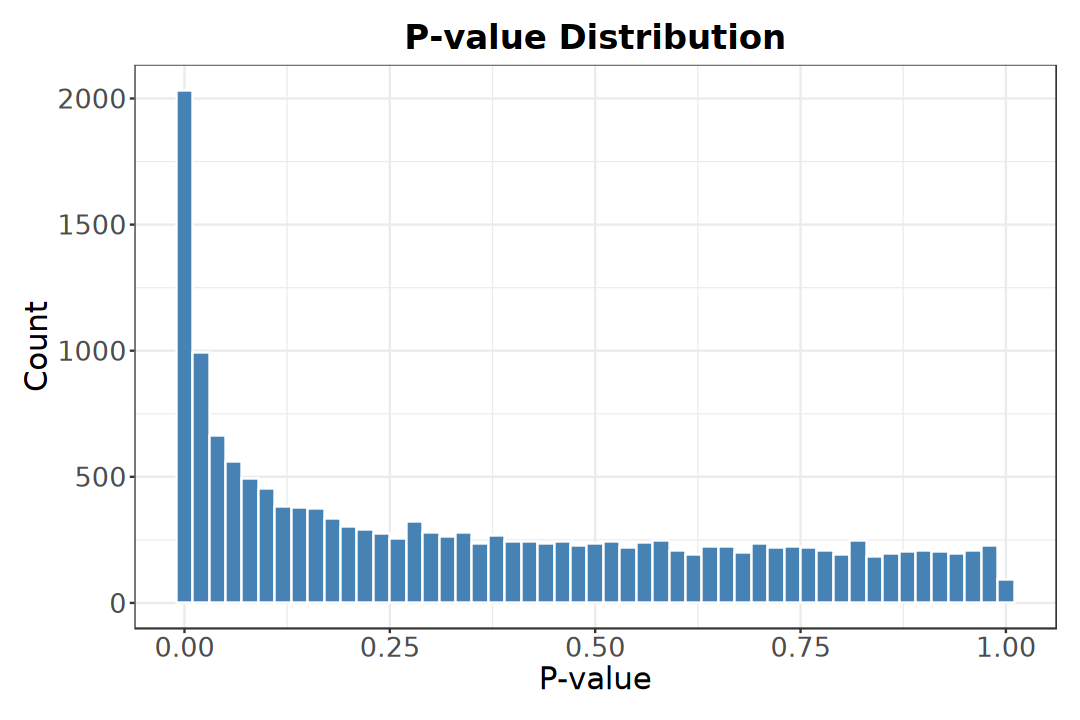

In [117]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(deseq2_result, aes(x = pvalue)) +
    geom_histogram(binwidth = 0.02, fill = "steelblue", color = "white") +
    labs(
        title = "P-value Distribution", 
        x = "P-value", y = "Count") +
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text = element_text(size = 16))

### MA Plot

> - Mean-Difference plot
> - Bland-Altman plot

In [118]:
ggplot_maplot <- function(plot_df, col, log = FALSE, title = NULL) {
    if(log) {
        x_vals <- log2(plot_df[[col]] + 1)
    } else {
        x_vals <- plot_df[[col]]
    }

    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()

    ggplot(plot_df, aes(x = x_vals, y = logFC)) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        labs(
            title = paste0("MA plot (", title,")"), , color = "DEG",
            x = "Mean Expression", y = "log2FC") +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))
}

In [119]:
p1 <- ggplot_maplot(deseq2_result, col = "baseMean", log = TRUE, title = "DESeq2")
p2 <- ggplot_maplot(edger_result, col = "logCPM", title = "edgeR")
p3 <- ggplot_maplot(limma_result, col = "AveExpr", title = "limma-voom")

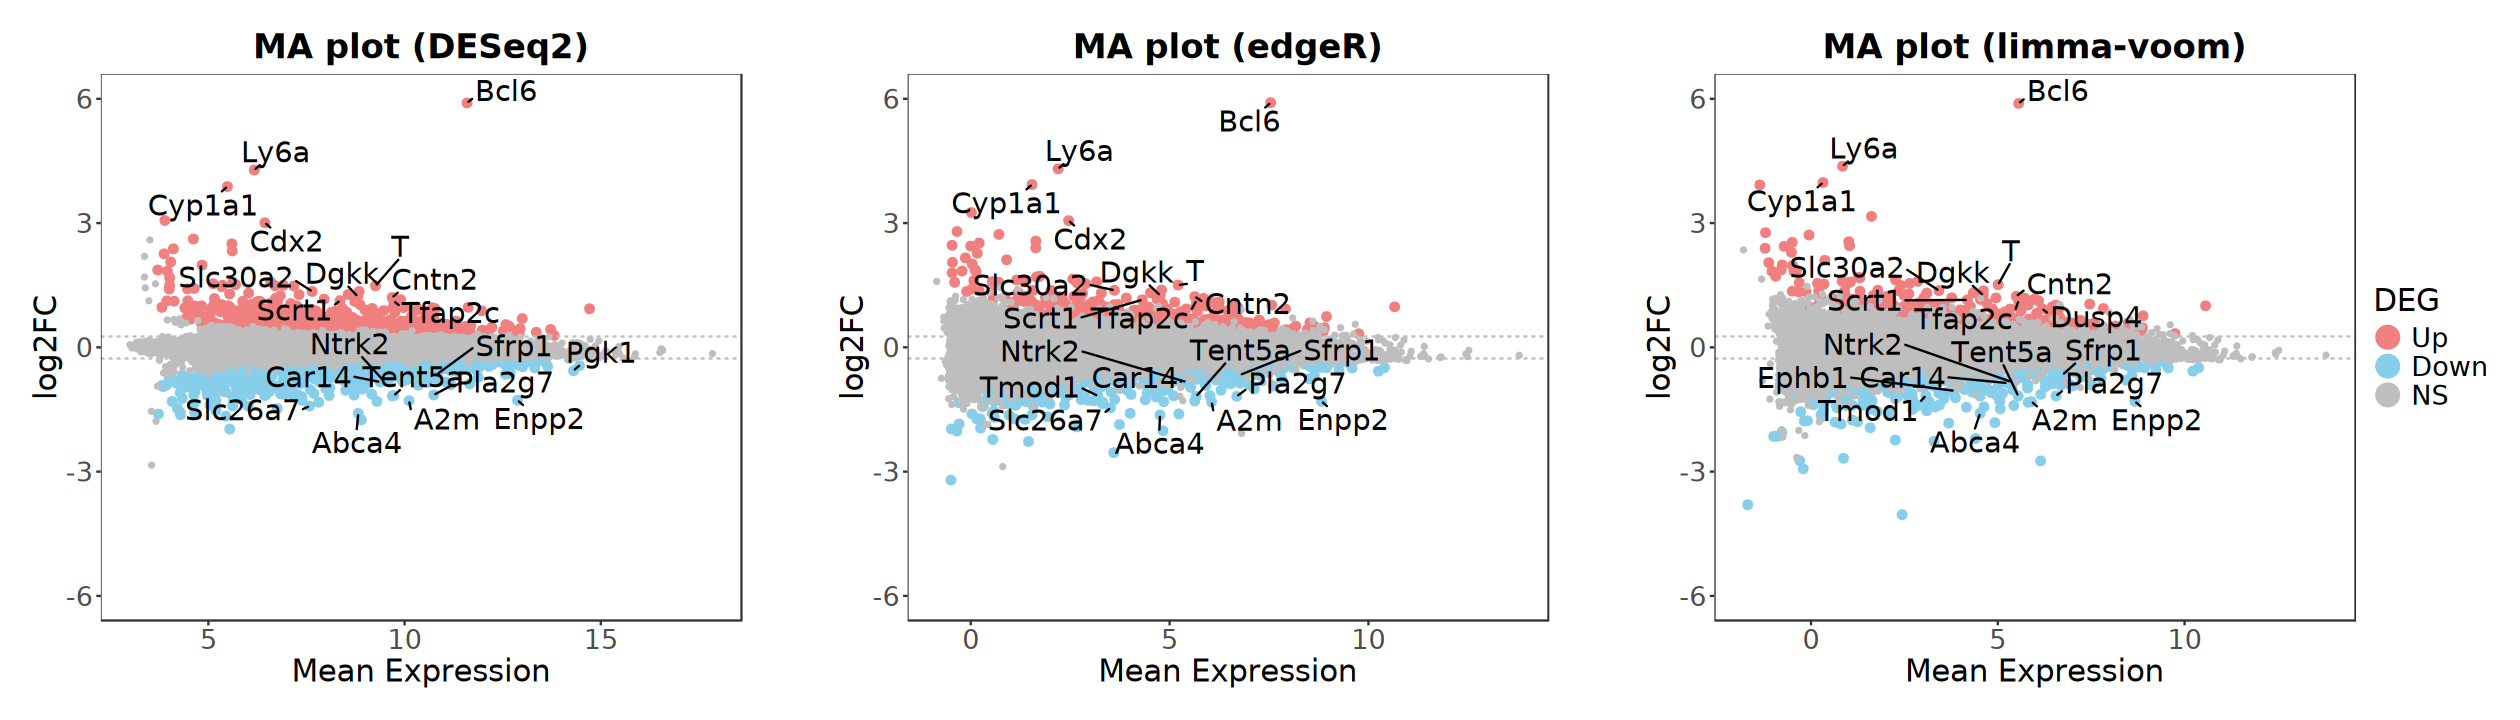

In [120]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Volcano

In [121]:
ggplot_volcano <- function(plot_df, title = NULL) {
    max_logfc <- plot_df$logFC |> abs() |> 
        max(na.rm = TRUE) |> ceiling()
    min_padj <- plot_df$padj |> pmax(1e-300) |> 
        (\(x) -log10(x))() |> max(na.rm = TRUE) |> 
        (\(x) ceiling(x / 5) * 5)()

    ggplot(plot_df, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
        geom_point(
            aes(color = result, size = result), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        ggrepel::geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 4, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_manual(
            values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
        scale_size_manual(
            values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
        labs(
            title = paste0("Volcano (", title,")"), , color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        guides(
            color = guide_legend(override.aes = list(size = 6))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18), 
            axis.text = element_text(size = 16))
}

In [122]:
p1 <- ggplot_volcano(deseq2_result, title = "DESeq2")
p2 <- ggplot_volcano(edger_result, title = "edgeR")
p3 <- ggplot_volcano(limma_result, title = "limma-voom")

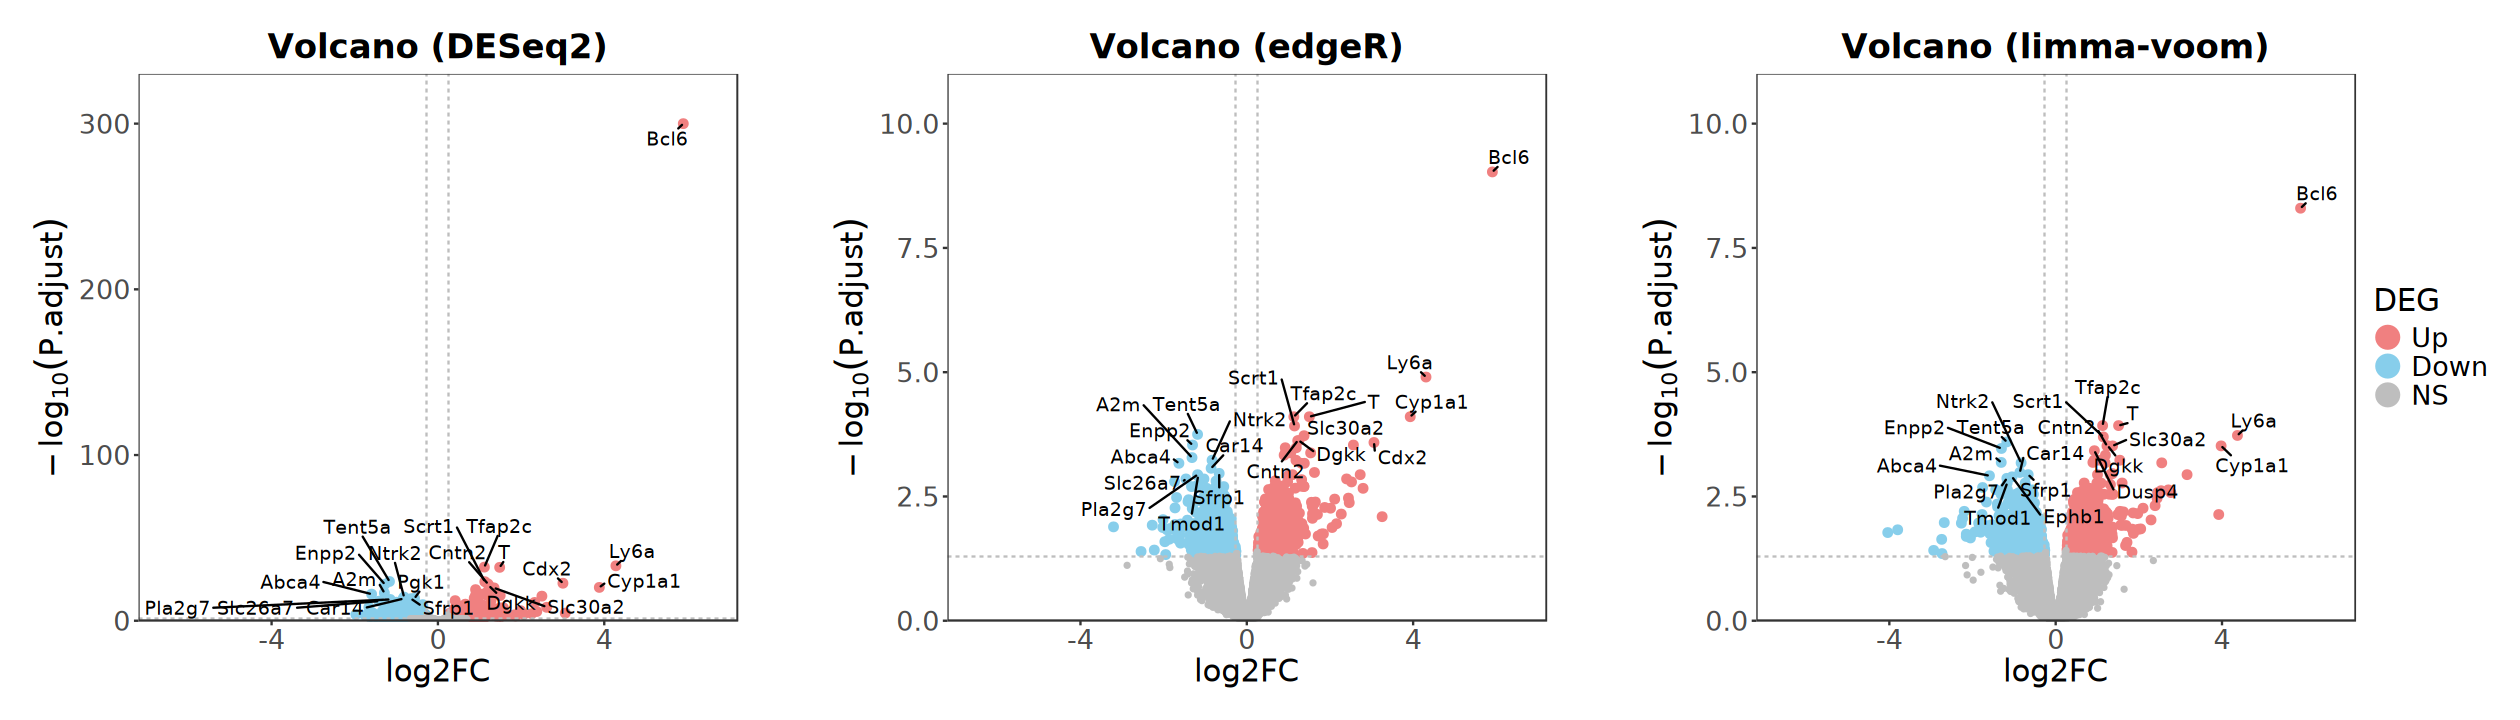

In [123]:
options(repr.plot.width = 21, repr.plot.height = 6)

p1 + plot_spacer() + p2 + plot_spacer() + p3 +
    plot_layout(
        nrow = 1, guides = "collect", 
        widths = c(1, 0.05, 1, 0.05, 1))

### Venn

In [124]:
suppressPackageStartupMessages(library(ggVennDiagram))

In [125]:
genes_up <- list(
    DESeq2 = deseq2_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Up") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Up") |> 
        pull(symbol) |> unique())

genes_down <- list(
    DESeq2 = deseq2_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    edgeR = edger_result |> filter(result == "Down") |> 
        pull(symbol) |> unique(),
    limma = limma_result |> filter(result == "Down") |> 
        pull(symbol) |> unique())

In [126]:
p1 <- ggVennDiagram(
    genes_up, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

p2 <- ggVennDiagram(
    genes_down, set_color = "grey", set_size = 6, 
    label_color = "firebrick", label_size = 5) +
    scale_fill_distiller(palette = "Reds", direction = 1)

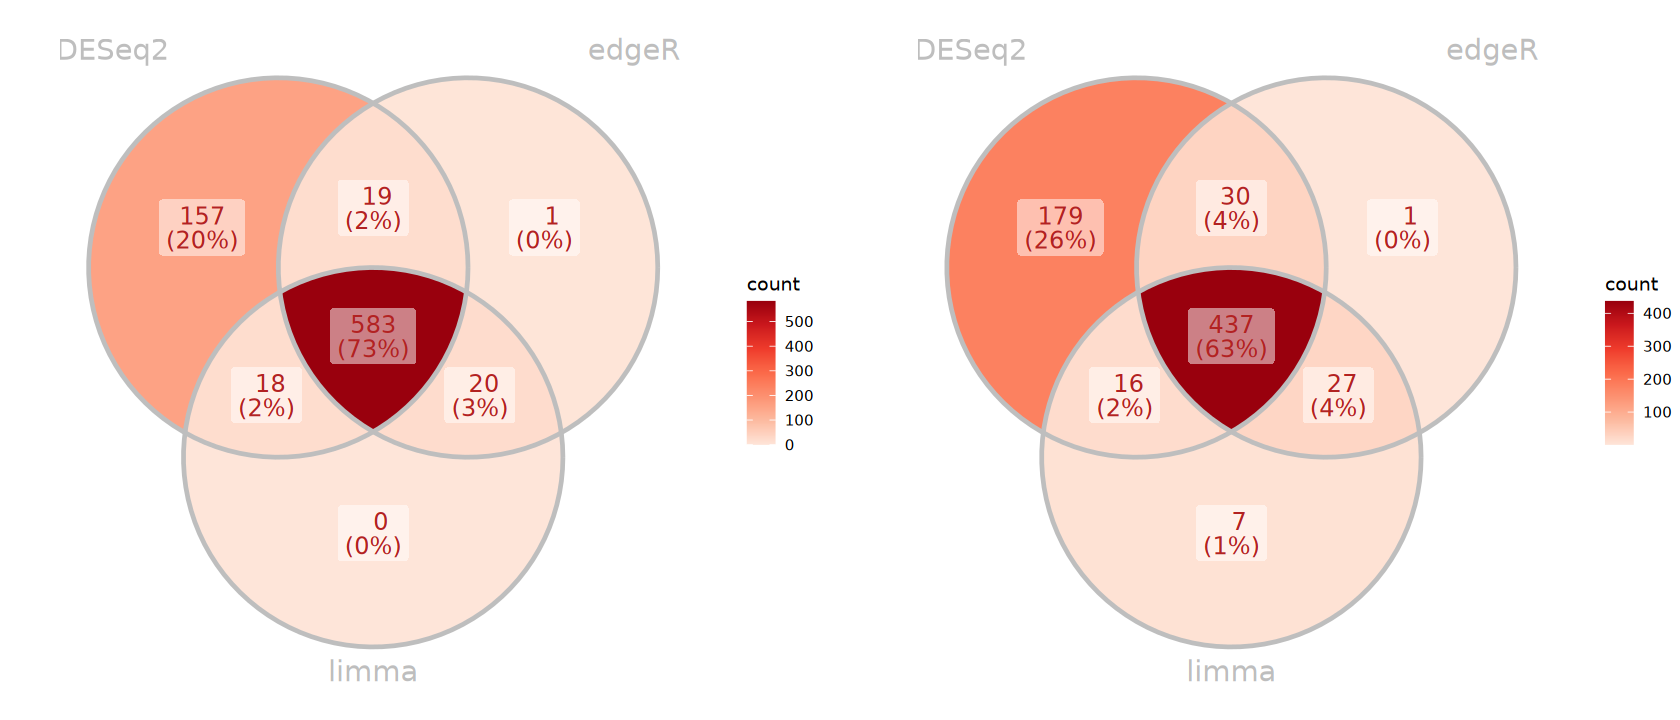

In [127]:
options(repr.plot.width = 14, repr.plot.height = 6)

p1 + plot_spacer() + p2 +
    plot_layout(nrow = 1, widths = c(1, 0.05, 1))

### Upset

In [128]:
suppressPackageStartupMessages(library(UpSetR))

Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors."
Warning message:
"The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.
ℹ The deprecated feature was likely used in the UpSetR package.
  Please report the issue to the authors."


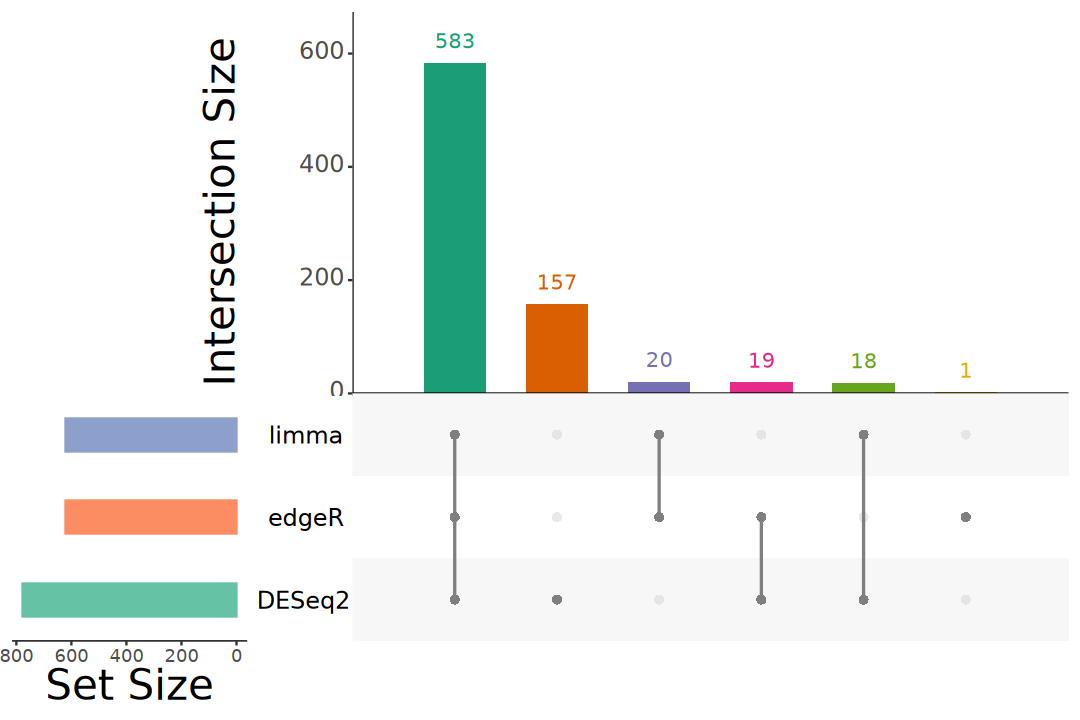

In [129]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_up), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 6, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

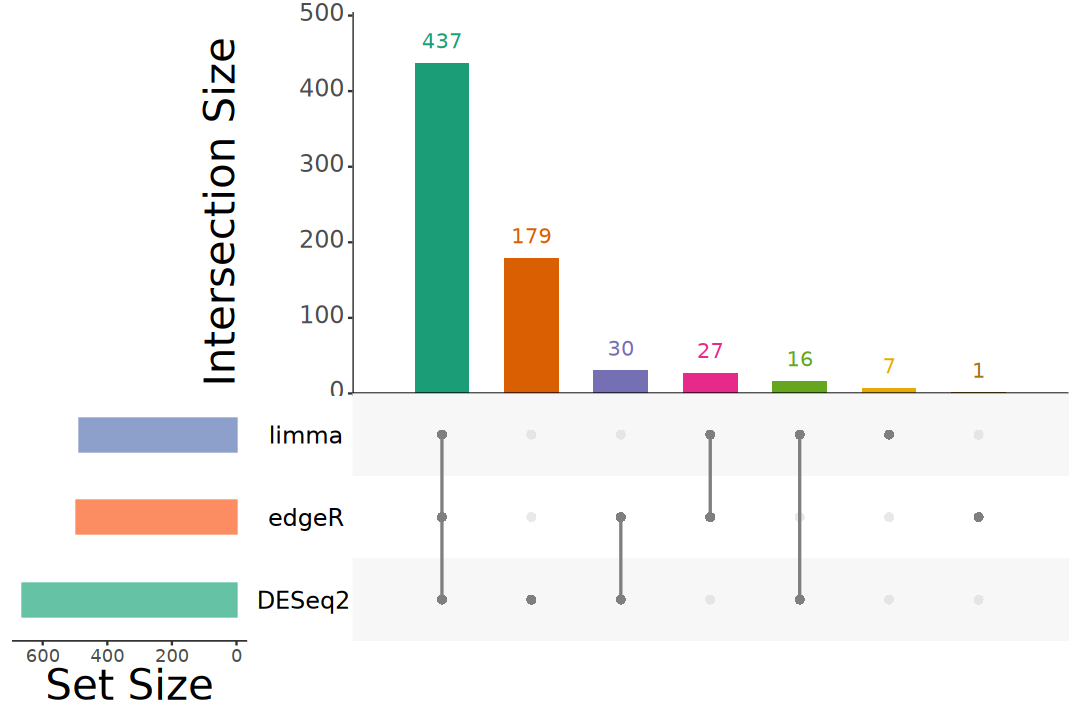

In [130]:
options(repr.plot.width = 9, repr.plot.height = 6)
UpSetR::upset(
    fromList(genes_down), mb.ratio = c(0.55, 0.45),
    order.by = "freq", decreasing = TRUE,
    sets.bar.color = brewer.pal(n = 3, name = "Set2"),
    main.bar.color = brewer.pal(n = 7, name = "Dark2"),
    matrix.color = "grey50",
    text.scale = c(3, 2, 3, 1.5, 2, 2))

## DEGs Visualization

In [131]:
res_lfc <- lfcShrink(dds, coef = "Group_cKO_vs_Ctrl", type = "apeglm")
summary(res_lfc)

using 'apeglm' for LFC shrinkage. If used in published research, please cite:
    Zhu, A., Ibrahim, J.G., Love, M.I. (2018) Heavy-tailed prior distributions for
    sequence count data: removing the noise and preserving large differences.
    Bioinformatics. https://doi.org/10.1093/bioinformatics/bty895




out of 16126 with nonzero total read count
adjusted p-value < 0.1
LFC > 0 (up)       : 1196, 7.4%
LFC < 0 (down)     : 1124, 7%
outliers [1]       : 1, 0.0062%
low counts [2]     : 626, 3.9%
(mean count < 12)
[1] see 'cooksCutoff' argument of ?results
[2] see 'independentFiltering' argument of ?results



In [132]:
degs_result <- res_lfc |> as.data.frame() |> 
    rownames_to_column("gene_id") |>
    dplyr::rename(logFC = log2FoldChange) |>
    mutate(
        result = case_when(
            padj < p_cutoff & logFC >  logfc_cutoff ~ "Up",
            padj < p_cutoff & logFC < -logfc_cutoff ~ "Down",
            TRUE ~ "NS") |> 
            factor(levels = c("Up", "Down", "NS"))) |>
    left_join(
        rowData(dds) |> 
            as.data.frame() |> 
            dplyr::select(symbol, type, basepairs) |>
            rownames_to_column("gene_id"), 
        by = "gene_id") |>
    group_by(result) |>
    arrange(padj, logFC |> abs() |> desc()) |>
    mutate(
        label = ifelse(
            type == "protein_coding" & 
                result %in% c("Up", "Down") & 
                row_number() <= 5, 
            symbol, NA_character_)) |>
    ungroup() |>
    column_to_rownames("gene_id")

table(degs_result$result)
head(degs_result)


   Up  Down    NS 
  777   662 14687 

,baseMean,logFC,lfcSE,pvalue,padj,result,symbol,type,basepairs,label
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>,<chr>,<int>,<chr>
ENSMUSG00000022508.5,3086.6635,5.900680,0.13893258,0.000000e+00,0.000000e+00,Up,Bcl6,protein_coding,6700,Bcl6
ENSMUSG00000075602.10,70.9492,4.280436,0.33581960,8.915646e-38,6.909180e-34,Up,Ly6a,protein_coding,1205,Ly6a
ENSMUSG00000028640.11,844.3063,1.117026,0.08969967,8.087251e-37,4.178143e-33,Up,Tfap2c,protein_coding,3679,Tfap2c
ENSMUSG00000062327.10,611.8264,1.485076,0.11978872,1.527854e-36,5.920052e-33,Up,T,protein_coding,2315,T
ENSMUSG00000032265.14,844.9143,-1.165171,0.10898266,6.440247e-28,1.996348e-24,Down,Tent5a,protein_coding,5703,Tent5a
ENSMUSG00000048385.9,326.3546,1.128332,0.10590586,1.031302e-27,2.664026e-24,Up,Scrt1,protein_coding,4380,Scrt1


In [133]:
max_logfc <- degs_result$logFC |> abs() |> 
    max(na.rm = TRUE) |> 
    ceiling()

min_padj <- degs_result$padj |> pmax(1e-300) |>
    (\(x) -log10(x))() |>
    max(na.rm = TRUE) |>
    (\(x) ceiling(x / 5) * 5)()

### MA plot

> - Mean-Difference plot
> - Bland-Altman plot

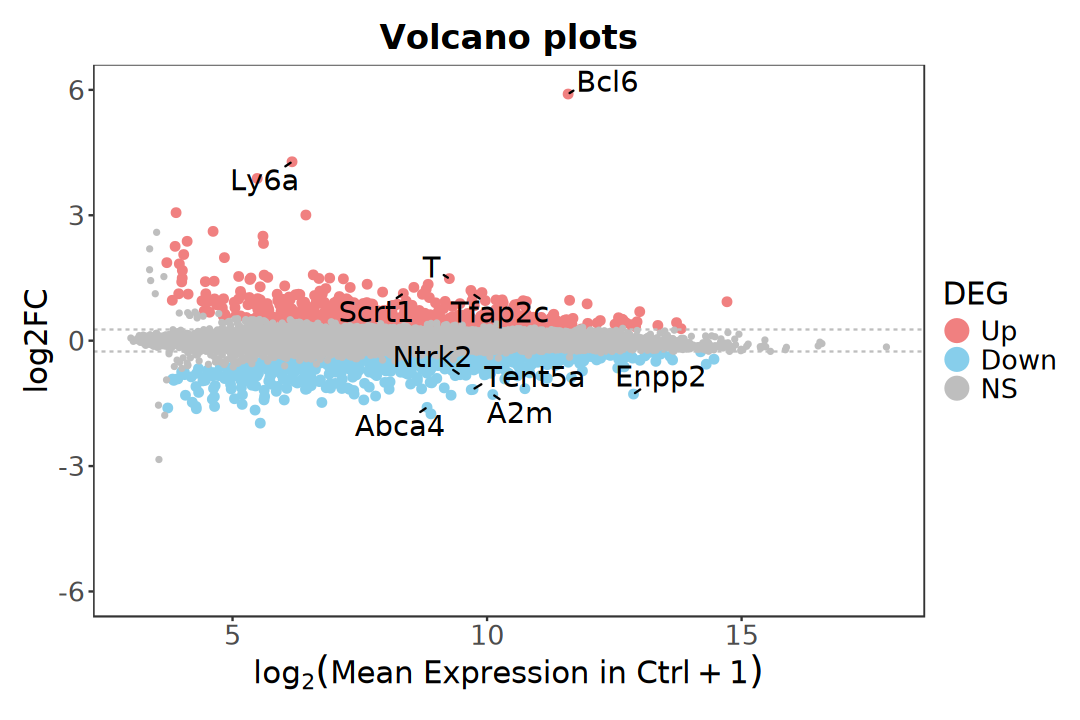

In [134]:
options(repr.plot.width = 9, repr.plot.height = 6)

ggplot(degs_result, aes(x = log2(baseMean + 1), y = logFC)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_y_continuous(limits = c(-max_logfc, max_logfc)) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = "log2FC") +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Volcano

In [135]:
p1 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_manual(
        values = c(
            Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(
            Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [136]:
p2 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = logFC, size = logFC), na.rm = TRUE) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
    scale_color_gradientn(
        colours = brewer.pal(11, 'RdYlBu') |> rev(), 
        limits = c(-max_logfc, max_logfc)) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

In [137]:
p3 <- degs_result |>
    mutate(
        neglog10_padj = -log10(pmax(padj, 1e-300)), 
        neglog10_padj_m = ifelse(
            logFC < 0, -neglog10_padj, neglog10_padj)) |>
    ggplot(aes(x = logFC, y = neglog10_padj)) +
        geom_point(
            aes(color = neglog10_padj_m, size = neglog10_padj), na.rm = TRUE) +
        geom_hline(
            yintercept = -log10(p_cutoff), 
            linetype = "dashed", color = "gray") + 
        geom_vline(
            xintercept = c(-logfc_cutoff, logfc_cutoff),
            linetype = "dashed", color = "gray") +
        geom_text_repel(
            aes(label = label), color = "black", na.rm = TRUE, size = 6, 
            min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
        scale_x_continuous(
            expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
        scale_y_continuous(
            expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) + 
        scale_color_gradientn(
            name = expression(-log[10](P.adjust)),
            colours = brewer.pal(11, 'RdBu') |> rev(), 
            limits = c(-min_padj, min_padj),
            breaks = c(-min_padj, 0, min_padj),
            labels = c(min_padj, 0, min_padj)) +
        scale_size_continuous(range = c(1, 3), guide = "none") +
        labs(
            title = "Volcano plots", color = "DEG",
            x = "log2FC", y = expression(-log[10](P.adjust))) +
        theme_test() + 
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
            plot.margin = unit(c(1, 1, 1, 1), "line"),
            legend.title = element_text(size = 18), 
            legend.text = element_text(size = 16),
            legend.key.size = unit(1, "cm"),
            axis.title = element_text(size = 18),
            axis.text = element_text(size = 16))

In [138]:
p4 <- ggplot(degs_result, aes(x = logFC, y = -log10(pmax(padj, 1e-300)))) +
    geom_point(
        aes(color = -log10(pmax(padj, 1e-300)), size = -log10(pmax(padj, 1e-300))),
        na.rm = TRUE, alpha = 0.8) +
    geom_hline(
        yintercept = -log10(p_cutoff), 
        linetype = "dashed", color = "gray") + 
    geom_vline(
        xintercept = c(-logfc_cutoff, logfc_cutoff),
        linetype = "dashed", color = "gray") +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_x_continuous(
        expand = c(0.1, 0), limits = c(-max_logfc, max_logfc)) +
    scale_y_continuous(
        expand = expansion(mult = c(0, 0.1)), limits = c(0, min_padj)) +  
    # scale_color_viridis_c(
    #     option = "turbo", begin = 0.1, end = 0.9) + 
    # scale_color_gradientn(
    #     colours = brewer.pal(11, 'RdYlBu') |> rev())+
    # scale_color_gradientn(
    #     colors = c("#39489f","#39bbec","#f9ed36","#f38466","#b81f25")) +
    scale_color_gradientn(
        colors = c(
            "#5E4FA2", "#3288BD", "#66C2A5", "#ABDDA4", 
            "#E6F598", "#FFFFBF", "#FEE08B", "#FDAE61", 
            "#F46D43", "#D53E4F", "#9C2007", "#9E0142")) +
    scale_size_continuous(range = c(1, 3), guide = "none") +
    labs(
        title = "Volcano plots", 
        color = expression(-log[10](P.adjust)),
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        legend.key.size = unit(1, "cm"),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

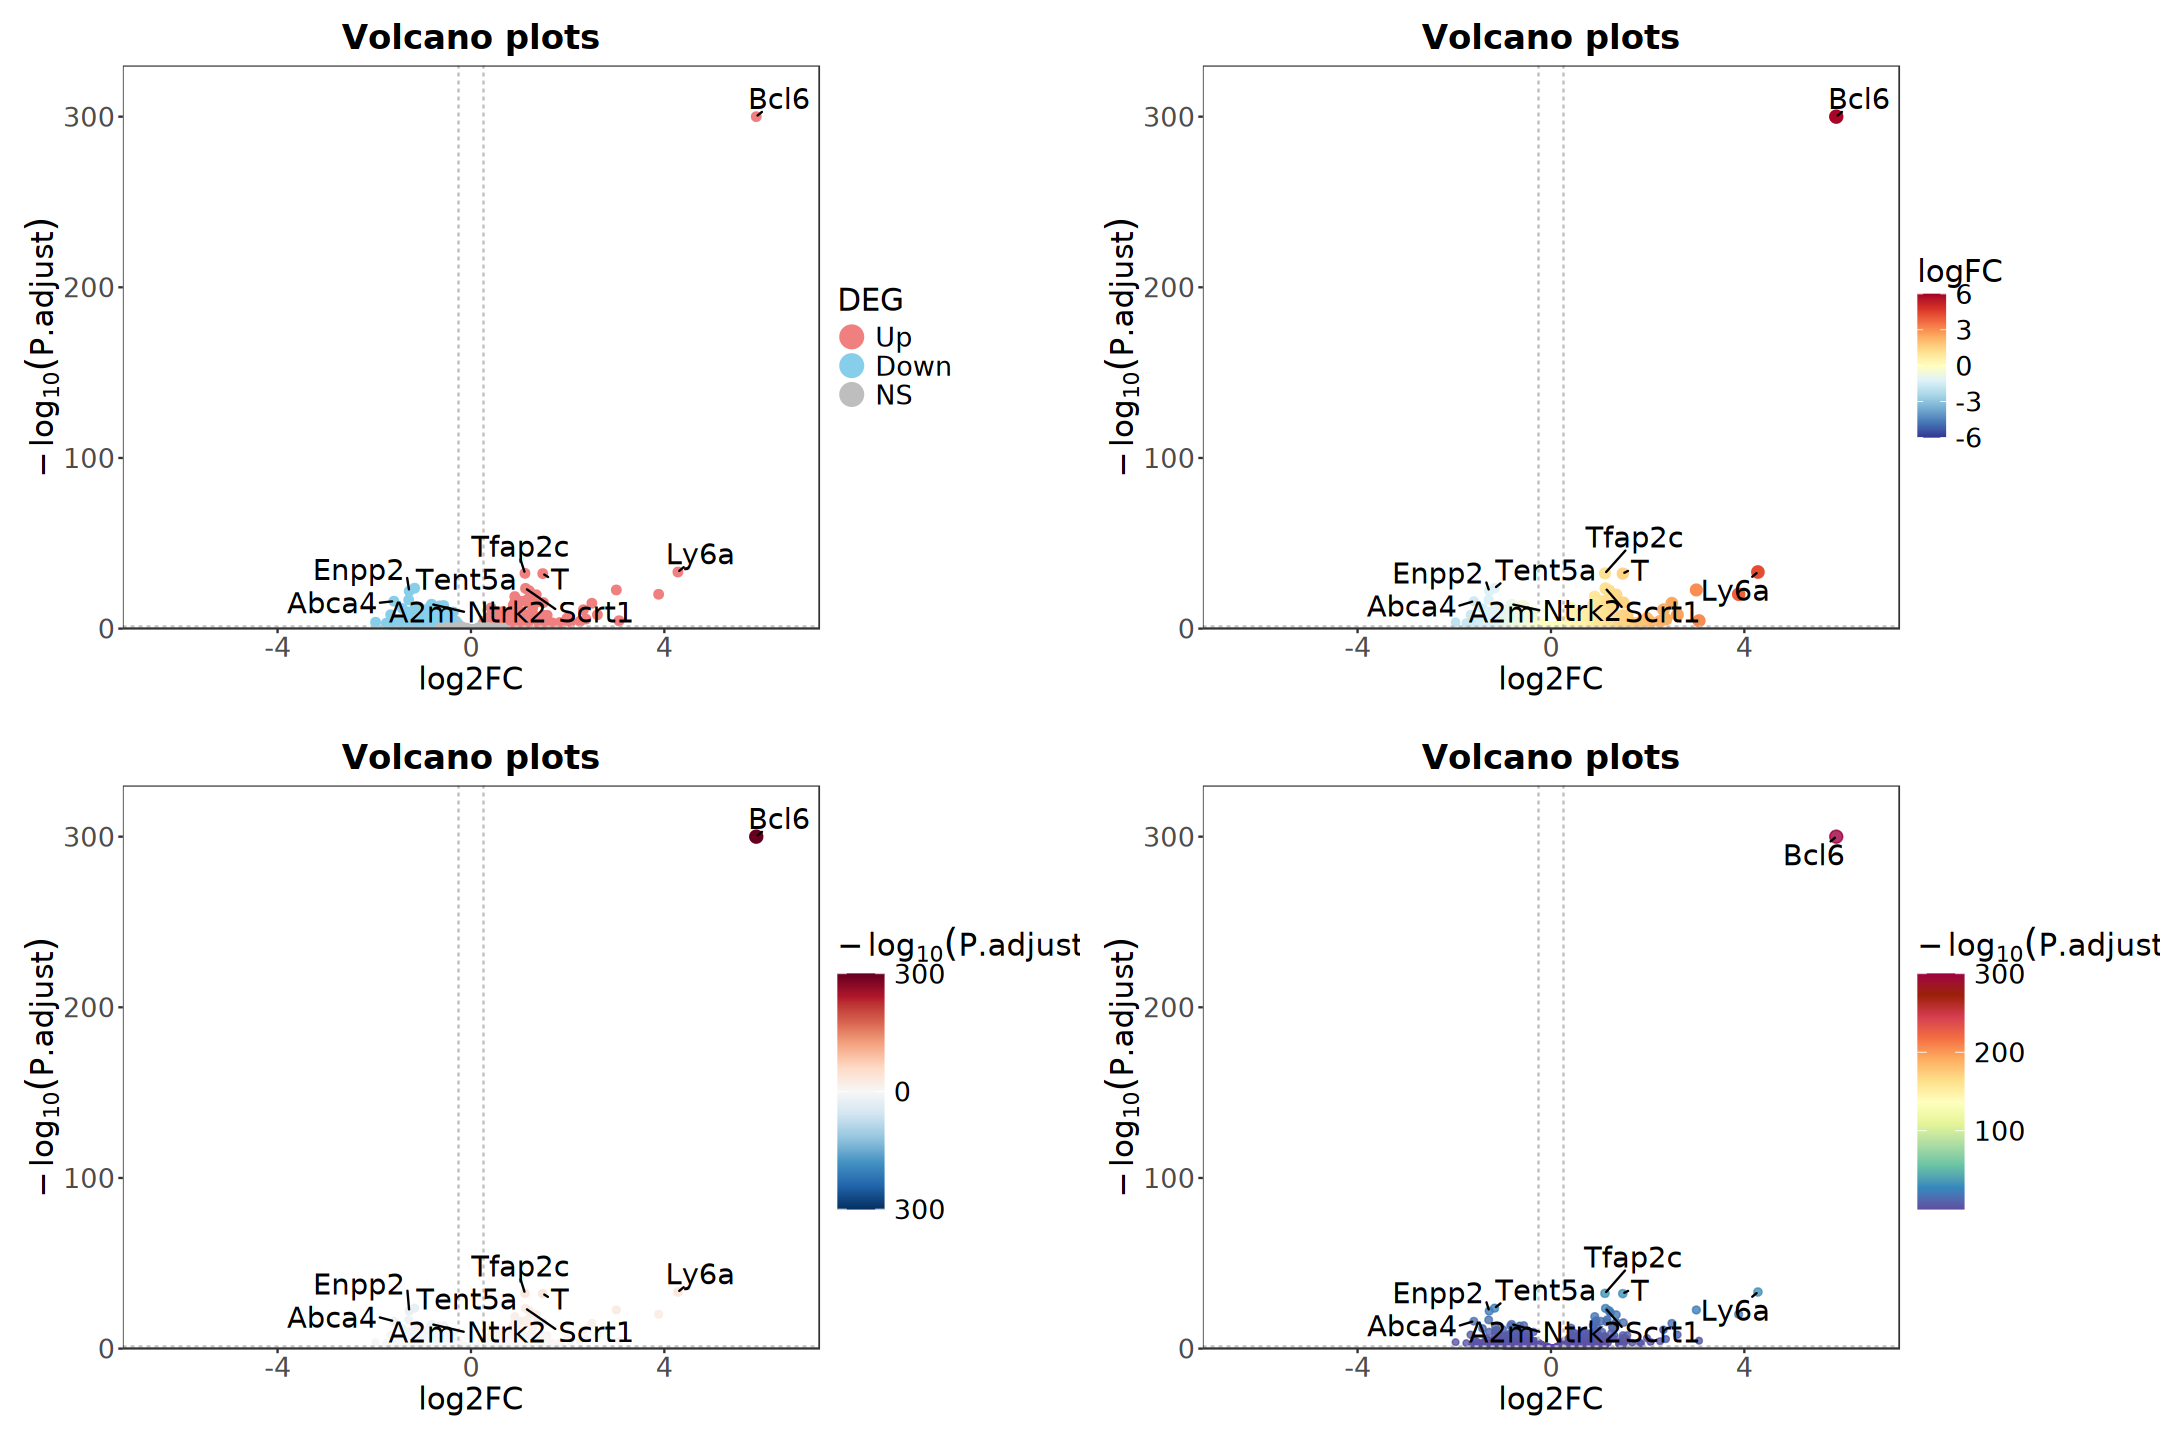

In [139]:
options(repr.plot.width = 18, repr.plot.height = 12)
cowplot::plot_grid(
    p1, p2, p3, p4, nrow = 2, align = "hv", axis = "tblr")

### Scatter Plot

In [140]:
ctrl_samples <- colnames(dds)[dds$Group == "Ctrl"]
treat_samples <- colnames(dds)[dds$Group == "cKO"]

mean_expr <- dds |> 
    counts(normalized = TRUE) |> 
    as.data.frame() |> 
    rownames_to_column(var = "gene_id") |> 
    mutate(
        Ctrl_Mean = rowMeans(across(all_of(ctrl_samples))),
        Treat_Mean = rowMeans(across(all_of(treat_samples)))) |> 
    dplyr::select(gene_id, Ctrl_Mean, Treat_Mean)

In [141]:
plot_df <- degs_result |> 
    rownames_to_column(var = "gene_id") |> 
    inner_join(mean_expr, by = "gene_id") |> 
    mutate(
        log2_Ctrl = log2(Ctrl_Mean + 1),
        log2_Treat = log2(Treat_Mean + 1)) |> 
    drop_na(log2_Ctrl, log2_Treat)

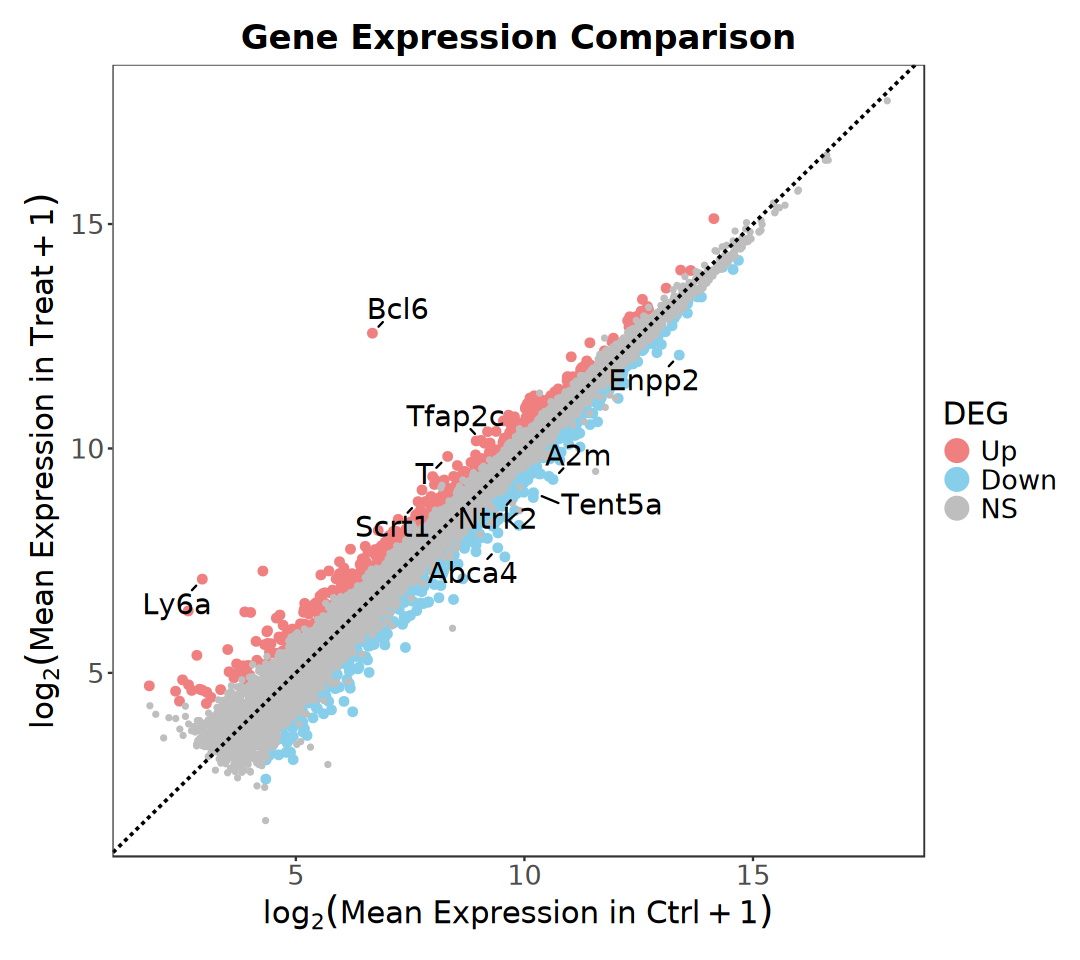

In [142]:
options(repr.plot.width = 9, repr.plot.height = 8)

ggplot(plot_df, aes(x = log2_Ctrl, y = log2_Treat)) +
    geom_point(
        aes(color = result, size = result), na.rm = TRUE) +
    geom_abline(
        intercept = 0, slope = 1, linetype = "dashed", 
        color = "black", linewidth = 0.8) +
    geom_text_repel(
        aes(label = label), color = "black", na.rm = TRUE, size = 6, 
        box.padding = 0.5, point.padding = 0.3,
        min.segment.length = 0, segment.size = 0.5, max.overlaps = Inf) +
    scale_color_manual(
        values = c(Up = "LightCoral", Down = "SkyBlue", NS = "gray")) +
    scale_size_manual(
        values = c(Up = 2, Down = 2, NS = 1), guide = "none") +
    guides(
        color = guide_legend(override.aes = list(size = 6))) +
    labs(
        title = "Volcano plots", color = "DEG",
        x = "log2FC", y = expression(-log[10](P.adjust))) +
    labs(
        title = "Gene Expression Comparison",
        x = expression(log[2]("Mean Expression in Ctrl" + 1)),
        y = expression(log[2]("Mean Expression in Treat" + 1))) + 
    theme_test() + 
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18),
        axis.text = element_text(size = 16))

### Heatmap

In [143]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [144]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Group)

In [145]:
group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))
deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

anno_colors <- list(
    Group = group_colors, Replicate = replicate_colors, DEG = deg_colors, 
    logFC = colorRampPalette(brewer.pal(9, "PiYG"))(255) |> rev())

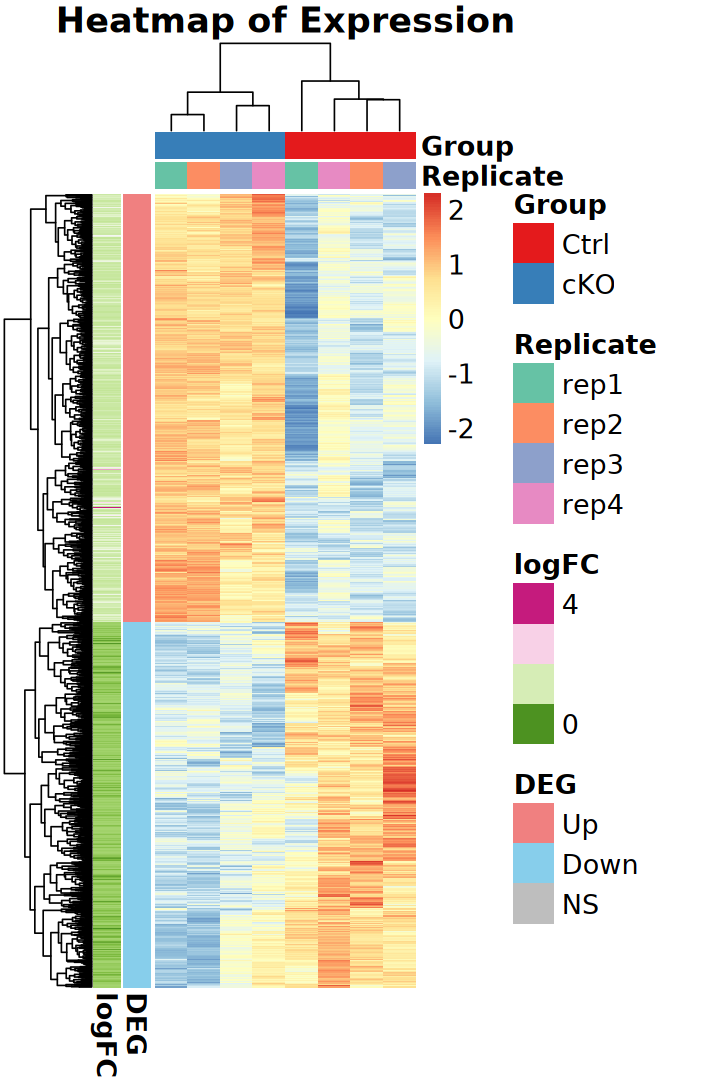

In [146]:
options(repr.plot.width = 6, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, 
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = FALSE)

In [147]:
lr <- degs_result |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    arrange(factor(gene_id, levels = rownames(heatmap_dat))) |>
    pull(label) |>
    replace_na("")

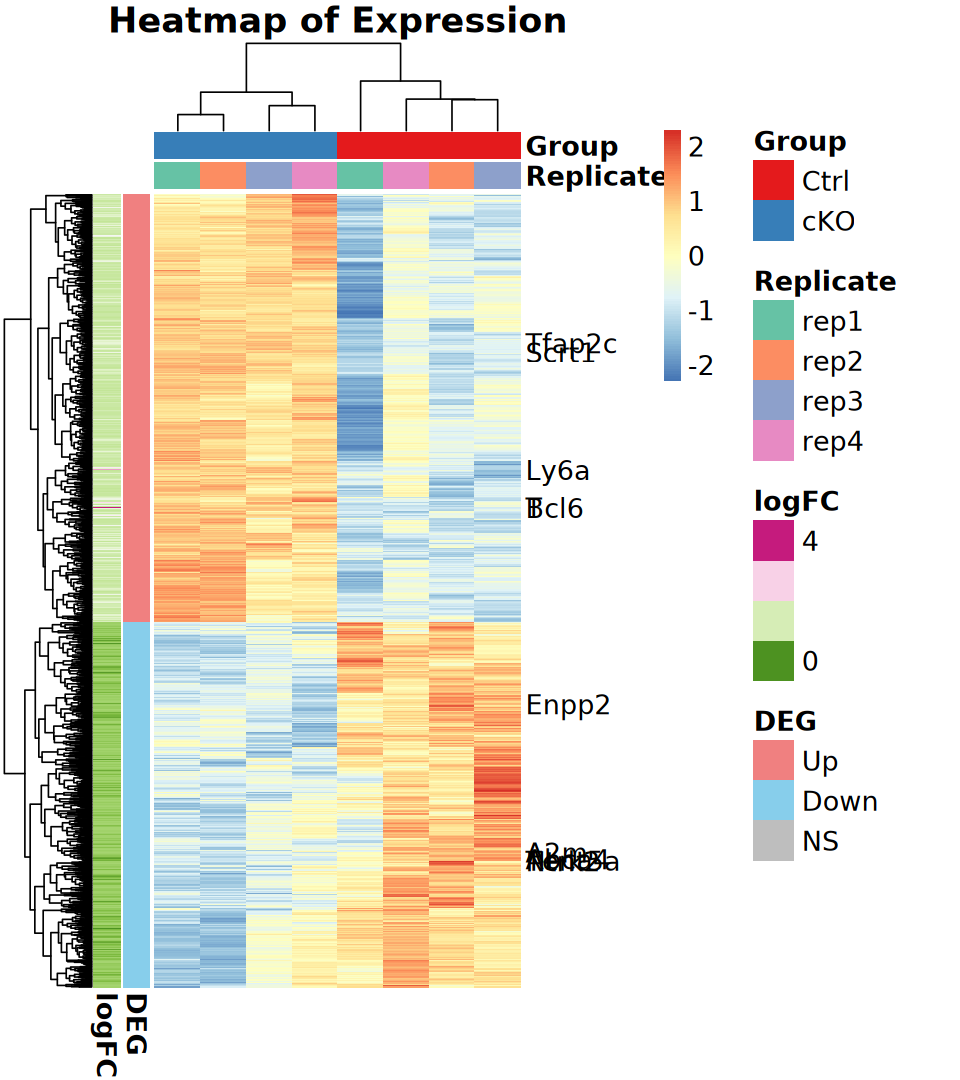

In [148]:
options(repr.plot.width = 8, repr.plot.height = 9)

pheatmap::pheatmap(
    heatmap_dat, scale = "row",
    annotation_row = ar, annotation_col = ac, 
    annotation_colors = anno_colors, labels_row = lr,
    main = "Heatmap of Expression", fontsize = 16, 
    show_colnames = FALSE, show_rownames = TRUE)

### ComplexHeatmap

In [149]:
# suppressPackageStartupMessages(library(circlize))
suppressPackageStartupMessages(library(ComplexHeatmap))

In [150]:
heatmap_dat <- degs_result |>
    filter(result %in% c("Up", "Down")) |>
    rownames() |>
    (\(idx) norm_mat[idx, ])()

In [151]:
heatmap_col <- circlize::colorRamp2(
    breaks = c(-2, 0, 2), 
    colors = brewer.pal(n = 11, name = "RdYlBu")[c(3,6,9)] |> rev())

group_colors <- setNames(
    scales::brewer_pal(palette = "Set1")(nlevels(dds$Group)),
    levels(dds$Group))
replicate_colors <- setNames(
    scales::brewer_pal(palette = "Set2")(nlevels(dds$Replicate)),
    levels(dds$Replicate))

deg_colors <- c(Up = "LightCoral", Down = "SkyBlue", NS = "grey")

In [152]:
ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Group, Replicate)

top_anno <- HeatmapAnnotation(
    df = ac, col = list(
        Group = group_colors, 
        Replicate = replicate_colors))

In [153]:
ar <- degs_result |> 
    dplyr::select(logFC, DEG = result) |>
    rownames_to_column("gene_id") |>
    filter(gene_id %in% rownames(heatmap_dat)) |>
    column_to_rownames("gene_id")

anno_colors <- list(
    DEG = deg_colors, 
    logFC = circlize::colorRamp2(
        breaks = c(-5, 0, 5),
        colors = rev(brewer.pal(n = 3, name = "PiYG"))))

left_anno <- rowAnnotation(
    df = ar, col = anno_colors, show_legend = FALSE)

In [154]:
right_anno <- rowAnnotation(
    foo = anno_mark(
        at = which(!is.na(degs_result$label)),
        labels = degs_result$symbol[which(!is.na(degs_result$label))],
        labels_gp = gpar(fontsize = 12)))

In [155]:
ar <- degs_result |> 
    dplyr::select(DEG = result, logFC)

ac <- colData(dds) |> as.data.frame() |>
    dplyr::select(Replicate, Group)

In [156]:
lg_heatmap <- Legend(
    title = "Expression (z-score)", col_fun = heatmap_col)
lg_group <- Legend(
    title = "Group", labels = levels(dds$Group))
lg_replicate <- Legend(
    title = "Replicate", labels = levels(dds$Replicate))
lg_logfc <- Legend(
    title = "logFC", col_fun = anno_colors$logFC)
lg_deg <- Legend(
    labels = levels(degs_result$result), title = "DEG", 
    legend_gp = gpar(fill = deg_colors))

combined_leg <- list(lg_heatmap, lg_group, lg_replicate) |>
    packLegend(direction = "vertical")

In [157]:
ht <- heatmap_dat |> t() |> scale() |> t() |>
    Heatmap(
        name = "Expression", col = heatmap_col,
        top_annotation = top_anno,
        left_annotation = left_anno, 
        right_annotation = right_anno,
        show_row_names = FALSE, show_column_names = FALSE)

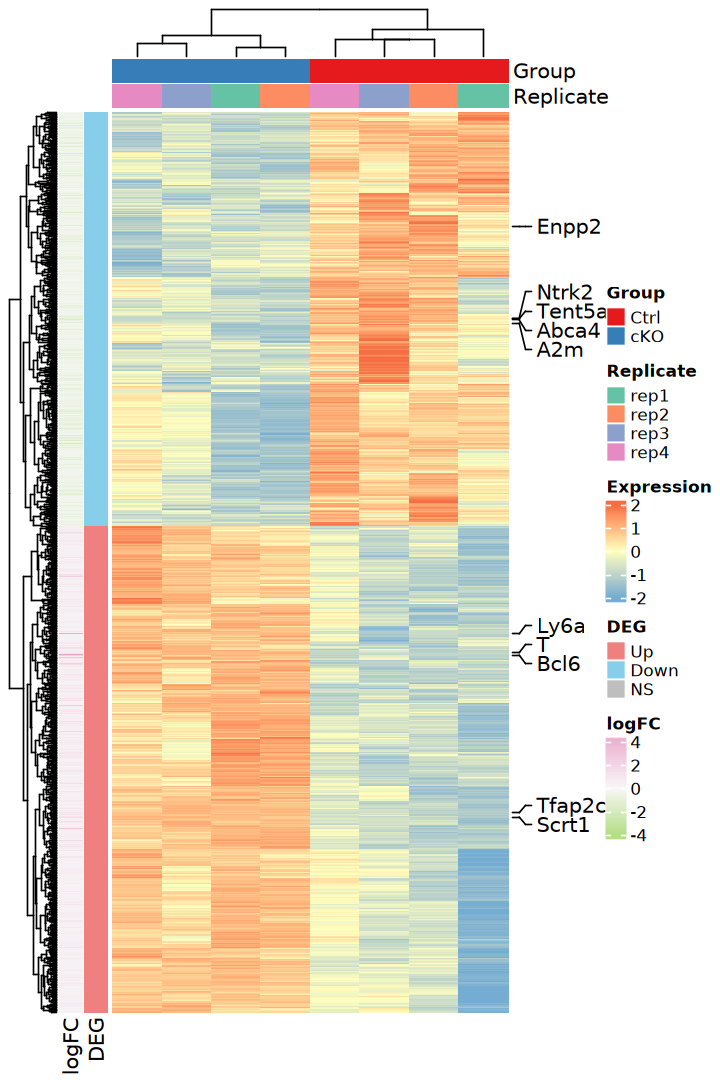

In [158]:
options(repr.plot.width = 6, repr.plot.height = 9)

draw(
    ht + combined_leg, merge_legend = TRUE,
    annotation_legend_list = list(lg_deg, lg_logfc), 
    legend_title_gp = gpar(fontsize = 12, fontface = "bold"),
    legend_labels_gp = gpar(fontsize = 10), 
    padding = unit(c(2, 2, 2, 5), "mm"))

# 6. Gene Function Analysis

## 1). ORA

> Over-Representation Analysis

In [159]:
suppressPackageStartupMessages(library(org.Mm.eg.db))
suppressPackageStartupMessages(library(clusterProfiler))

In [160]:
add_ENTREZID <- function(
    res, orgdb, fromType = "SYMBOL", toType = "ENTREZID", 
    ignoreVersion = FALSE) {
    
    gene_ids <- rownames(res)

    if(fromType == "ENSEMBL" & ignoreVersion) {
        gene_ids <- sub("\\..*$", "", gene_ids)
    }

    gene_map <- clusterProfiler::bitr(
        gene_ids, OrgDb = orgdb, drop = FALSE, 
        fromType = fromType, toType = toType)
    
    idx <- match(gene_ids, gene_map[[fromType]])

    for (col in toType) {
        res[[col]] <- gene_map[[col]][idx]
    }
    
    return(res)
}

In [161]:
deseq2_result <- add_ENTREZID(
    deseq2_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
edger_result <- add_ENTREZID(
    edger_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)
limma_result <- add_ENTREZID(
    limma_result, org.Mm.eg.db, fromType = "ENSEMBL", 
    toType = c("SYMBOL", "ENTREZID"), ignoreVersion = TRUE)

'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"6.94% of input gene IDs are fail to map..."
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"6.51% of input gene IDs are fail to map..."
'select()' returned 1:many mapping between keys and columns

Warning message in clusterProfiler::bitr(gene_ids, OrgDb = orgdb, drop = FALSE, :
"6.51% of input gene IDs are fail to map..."


In [162]:
extract_gene_lists <- function(
    results_map, gene_col = "SYMBOL", result_col = "result", 
    directions = c("Up", "Down")) {
        
    lapply(names(results_map), function(method) {
        lapply(directions, function(dir) {
            df <- results_map[[method]]
            df[[gene_col]][df[[result_col]] == dir]
        })
    }) |>
    unlist(recursive = FALSE) |>
    setNames(
        nm = as.vector(t(outer(
            names(results_map), directions, paste, sep = "-"))))
}

In [163]:
results_map <- list(
    DESeq2 = deseq2_result, 
    edgeR  = edger_result,
    limma  = limma_result)

genes_list <- extract_gene_lists(
    results_map, gene_col = "symbol", result_col = "result")

In [164]:
ego_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichGO, 
    universe = unique(c(deseq2_result$SYMBOL, edger_result$SYMBOL)), 
    OrgDb = org.Mm.eg.db, ont = "ALL", 
    keyType = 'SYMBOL', pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500, readable = TRUE)

In [165]:
ego_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,ONTOLOGY,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,BP,GO:0001525,angiogenesis,78/734,491/13936,0.1588595,3.016166,10.724281,7.514086e-19,3.560174e-15,2.722472e-15,78
2,DESeq2-Up,BP,GO:0006935,chemotaxis,54/734,324/13936,0.1666667,3.164396,9.294583,3.113904e-14,4.917893e-11,3.760722e-11,54
3,DESeq2-Up,BP,GO:0042330,taxis,54/734,324/13936,0.1666667,3.164396,9.294583,3.113904e-14,4.917893e-11,3.760722e-11,54
4,DESeq2-Up,BP,GO:0007409,axonogenesis,68/734,482/13936,0.1410788,2.678576,8.843424,6.565873e-14,7.777277e-11,5.947299e-11,68
5,DESeq2-Up,BP,GO:0007411,axon guidance,43/734,241/13936,0.1784232,3.387611,8.816022,1.323729e-12,1.208943e-09,9.244812e-10,43
6,DESeq2-Up,BP,GO:0097485,neuron projection guidance,43/734,242/13936,0.1776860,3.373612,8.782819,1.530954e-12,1.208943e-09,9.244812e-10,43


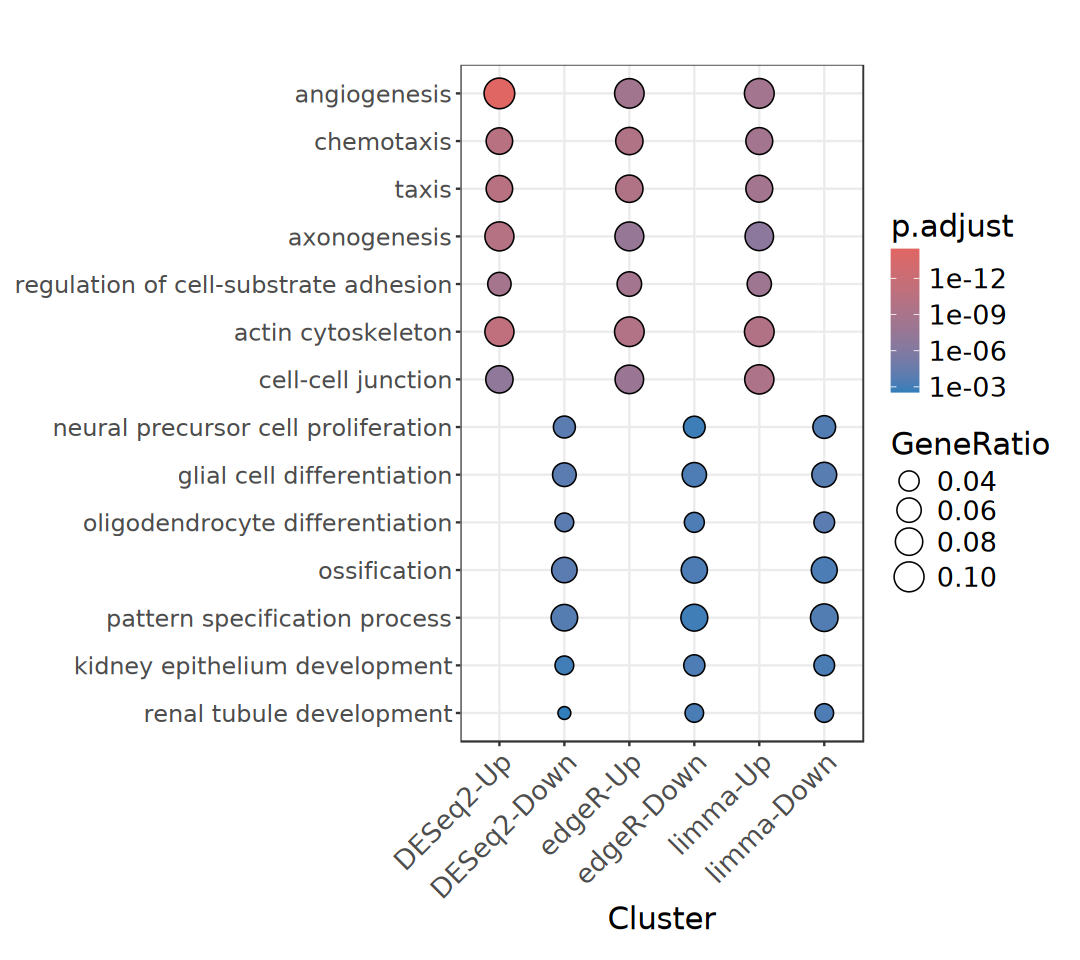

In [166]:
options(repr.plot.width = 9, repr.plot.height = 8)

dotplot(ego_compare, showCategory = 5, label_format = 50) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

In [167]:
genes_list <- extract_gene_lists(
    results_map, gene_col = "ENTREZID", result_col = "result")

In [ ]:
ekegg_compare <- compareCluster(
    geneCluster = genes_list, fun = enrichKEGG, 
    universe = unique(c(deseq2_result$ENTREZID, edger_result$ENTREZID)), 
    organism = "mmu", pAdjustMethod = "BH",
    pvalueCutoff = 0.01, qvalueCutoff = 0.05, 
    minGSSize = 10, maxGSSize = 500)

In [ ]:
ekegg_compare |> dplyr::select(-one_of("geneID")) |> head()

,Cluster,category,subcategory,ID,Description,GeneRatio,BgRatio,RichFactor,FoldEnrichment,zScore,pvalue,p.adjust,qvalue,Count
,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
1,DESeq2-Up,Environmental Information Processing,Signaling molecules and interaction,mmu04517,IgSF CAM signaling,39/373,248/6346,0.1572581,2.675495,6.725882,9.752204e-09,2.769626e-06,2.381591e-06,39
2,DESeq2-Up,Cellular Processes,Cell motility,mmu04820,Cytoskeleton in muscle cells,31/373,194/6346,0.1597938,2.718637,6.075063,2.424221e-07,3.442394e-05,2.960102e-05,31
3,DESeq2-Up,Cellular Processes,Cellular community - eukaryotes,mmu04530,Tight junction,24/373,145/6346,0.1655172,2.816012,5.527717,3.071875e-06,2.908042e-04,2.500614e-04,24
4,DESeq2-Up,Cellular Processes,Cell motility,mmu04810,Regulation of actin cytoskeleton,28/373,198/6346,0.1414141,2.405936,5.022329,1.101255e-05,7.047268e-04,6.059920e-04,28
5,DESeq2-Up,Environmental Information Processing,Signal transduction,mmu04668,TNF signaling pathway,18/373,98/6346,0.1836735,3.124911,5.297333,1.240716e-05,7.047268e-04,6.059920e-04,18
6,DESeq2-Up,Environmental Information Processing,Signaling molecules and interaction,mmu04518,Integrin signaling,20/373,132/6346,0.1515152,2.577789,4.577455,7.652616e-05,3.622238e-03,3.114749e-03,20


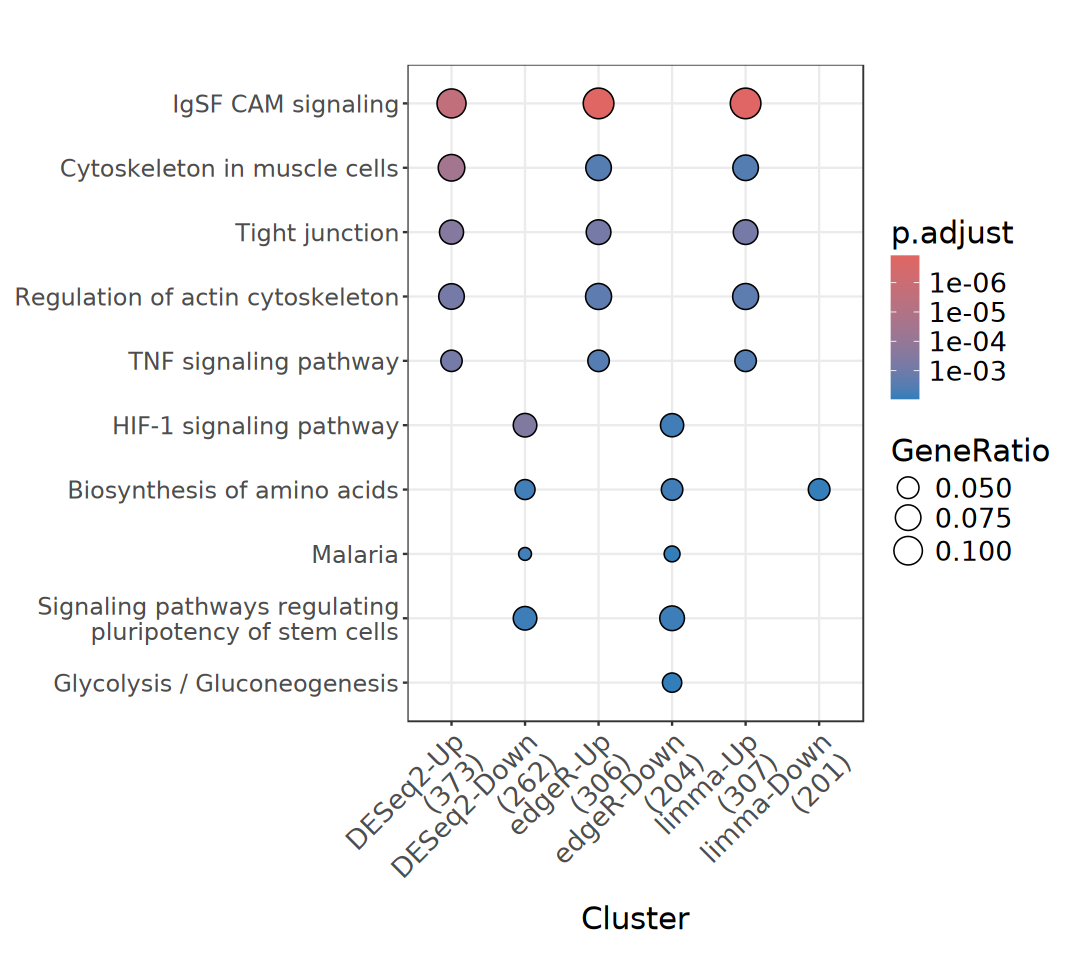

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 8)

dotplot(ekegg_compare, showCategory = 5, label_format = 40) + 
    theme_bw() +
    theme(
        plot.title = element_text(size = 20, face = "bold", hjust = 0.5), 
        plot.margin = unit(c(1, 1, 1, 1), "line"),
        legend.title = element_text(size = 18), 
        legend.text = element_text(size = 16),
        axis.title = element_text(size = 18), 
        axis.text.x = element_text(size = 16, angle = 45, hjust = 1), 
        axis.text.y = element_text(size = 14))

## 2). GSEA

> Gene Set Enrichment Analysis

# Reference

> 1. Law CW, Alhamdoosh M, Su S, Dong X, Tian L, Smyth GK, Ritchie ME (2018). “RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR.” F1000Research, 5, 1408. https://f1000research.com/articles/5-1408/v3. [RNA-seq analysis is easy as 1-2-3 with limma, Glimma and edgeR](https://www.bioconductor.org/packages/release/workflows/html/RNAseq123.html)
> 2. Law CW, Zeglinski K, Dong X, Alhamdoosh M, Smyth GK, Ritchie ME (2020). “A guide to creating design matrices for gene expression experiments.” F1000Research, 9, 1444. https://f1000research.com/articles/9-1444. [A guide to creating design matrices for gene expression experiments](https://www.bioconductor.org/packages/release/workflows/vignettes/RNAseq123/inst/doc/designmatrices.html)
> 2. Love MI, Anders S, Kim V, Huber W (2016). “RNA-Seq workflow: gene-level exploratory analysis and differential expression.” F1000Research. doi:10.12688/f1000research.7035.2. [RNA-seq workflow: gene-level exploratory analysis and differential expression](https://www.bioconductor.org/packages/release/workflows/html/rnaseqGene.html)
> 3. Chen Y, Lun ATL, Smyth GK (2016). “From reads to genes to pathways: differential expression analysis of RNA-Seq experiments using Rsubread and the edgeR quasi-likelihood pipeline.” F1000Research, 5, 1438. http://f1000research.com/articles/5-1438. [Gene-level RNA-seq differential expression and pathway analysis using Rsubread and the edgeR quasi-likelihood pipeline](https://www.bioconductor.org/packages/release/workflows/html/RnaSeqGeneEdgeRQL.html)